In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings


warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


In [3]:
#open pickle
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'rb') as file:
    big_df = pickle.load(file)

# fix mislabeled plate files and keep one recording per well per day
big_df = clean_recordings(big_df)

08.22.2025: 12 wells moved MAOA3 -> MAOA2
09.06.2025: 12 wells moved MAOA3 -> MAOA2
09.19.2025: 12 wells moved MAOA2 -> MAOA3
09.19.2025: 12 wells moved MAOA3 -> MAOA2
Dropped 48 duplicate well recordings (kept first recording of the day).


In [4]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

In [5]:
# Remove bad recording days and detached wells.
# The lists and the reason for each are in helper_files/maoa_plate_loader.py
# (BAD_RECORDING_DATES, EXCLUDED_WELLS); see also README "Data cleaning and exclusions".
big_df = apply_exclusions(big_df)

2025-09-26: removed 36 well recordings (bad recording)
2025-05-09: removed 36 well recordings (noise artefact: every electrode in every well fires ~0.8 Hz (~80x the neighbouring weeks), incl. normally silent KO wells; synchrony ~0)
MAOA76 A4 from 2025-09-25: removed 5 well recordings (GM organoid detached at the Sept re-plating; near-silent (0-5/64 active electrodes))


#### Mutant (c3, c71, c90), WT (c12, c30, c54) and GM

In [6]:
#Remove lines we are not using 
REMOVALS = {
    "MAOA1":{"H9", "C12", "C54","C90"},
    "MAOA2":{"H9", "C12", "C3", "C54","C90"},
    "MAOA3":{"H9", "C12", "C3", "C54","C90"},
    "MAOA72": {"C12", "C90", "C54", },
    "MAOA76": {"C12", "C90", "C54"},
    "MAOA77": {"C12", "C90", "C54"},
}

In [7]:
big_df = remove_clones_by_plate(big_df, REMOVALS)

Removed 402 rows based on plate-specific clone removal.


In [8]:
big_df

,well,firing_rate_stats_hz,burst_rate_stats_hz,network_event_rate_hz,synchrony_index,electrodes,firing_rate_vector_hz,burst_rate_vector_hz,recording_date,recording_date_str,plate_name,cell_line,organoid_age_days,spike_list_path,experiment
0,A2,"[1.4391208230357608, 1.6648439676442284]","[0.09436092897565711, 0.09586305971365496]",0.124031,0.022132,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[3.015680429868851, 0.0006597419448411399, 0.0...","[0.19066542205908946, nan, nan, nan, 0.0032987...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
1,A3,"[0.4052027312243695, 0.5762036681376207]","[0.018160265113258748, 0.024168885783248578]",0.003299,0.000282,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[nan, 0.0006597419448411399, 0.000659741944841...","[nan, nan, nan, nan, 0.00791690333809368, nan,...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
2,B1,"[2.0029325617413787, 2.347922067937726]","[0.1179549150855449, 0.11597167105563749]",0.032327,0.007995,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[2.4403854539673766, 0.0006597419448411399, 3....","[0.07653006560157223, nan, 0.16889393787933182...",2025-04-14,04.14.2025,MAOA2,C71,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
3,B2,"[1.821286102520696, 3.2362072623431377]","[0.1274676415928486, 0.11408226907420285]",0.148442,0.013659,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.0013194838896822799, 3.5289596629552578, 0....","[nan, 0.20188103512138883, nan, nan, 0.0936833...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
4,B3,"[0.7793130012355004, 1.3467926472630483]","[0.058214372561458665, 0.07832226183330862]",0.078509,0.001454,"[B3_11, B3_12, B3_13, B3_14, B3_15, B3_16, B3_...","[5.249566655100951, 0.0006597419448411399, nan...","[0.17747058316226666, nan, nan, 0.085106710884...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
956,A2,"[0.2001678022716308, 0.40852412447408004]","[0.03624468325620345, 0.03070101746160311]",0.008220,0.098530,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[nan, 0.0016440887250236617, 0.000822044362511...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,C71,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
957,B1,"[0.26199502345978026, 0.7419211332715153]","[0.02757010323501217, 0.025920461645713547]",0.000000,0.046000,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[nan, 0.0008220443625118308, 0.002466133087535...","[nan, nan, nan, nan, 0.01808497597526028, nan,...",2025-10-30,10.30.2025,MAOA76,C3,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
958,B2,"[0.4753718139533415, 1.490921272006652]","[0.03565617422395066, 0.04528512776359013]",0.000000,0.037999,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.024661330875354926, 0.17920567102757912, 0....","[nan, 0.007398399262606477, 0.0024661330875354...",2025-10-30,10.30.2025,MAOA76,C71,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
959,B4,"[0.010609510053668317, 0.045617147944364]","[0.01808497597526028, 0.0]",0.000000,-0.001633,"[B4_11, B4_12, B4_13, B4_14, B4_15, B4_16, B4_...","[0.004932266175070985, 0.0008220443625118308, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3


# Exp1 (MAOA1–3)
Same analysis as the Exp3 paper figure.

**Good data rule (same for all experiments):** a recording date is good if ≥ 40% of wells are active (mean firing ≥ 5 spikes/min); the window ends at the first date that fails. At 40% every Exp3 date passes (lowest: 52% at 8.5 months), so the Exp3 results are unchanged.

In [9]:
# Updated palette using the specific genetic strings as keys
MAOA_FIGURE_PALETTE = {
    "Xa:WT/Xi:MUT": "#9C899C", 
    "Xa:MUT/Xi:WT": "#EAC3EB", 
    "MAOA/B$^{-/Y}$": "#E980C0"  # Note the $ and ^
}

PLOT_ORDER = ["Xa:WT/Xi:MUT", "Xa:MUT/Xi:WT", "MAOA/B$^{-/Y}$"]


In [10]:
import importlib
import helper_files.mea_feats_analysis as _m
importlib.reload(_m)
from helper_files.mea_feats_analysis import (run_mea_analysis_for_figure, run_grouped_analysis,
    run_mea_analysis_by_clone, run_grouped_analysis_by_clone, get_experiment_datasets, experiment_age_range)

# Good-data window: >= 40% of wells active (well firing >= 5 spikes/min), up to the first day that fails.
# Same rule for every experiment; at 40% every Exp3 day is kept, so the Exp3 figure is unchanged.
datasets, quality = get_experiment_datasets(big_df, experiments=("Exp1", "Exp3"), min_active_frac=0.40)
print("Exp3:"); display(quality["Exp3"].round(3))
assert quality["Exp3"]["good"].all(), "rule would drop Exp3 dates"
print("Exp1:"); display(quality["Exp1"].round(3))

exp1_df = datasets["Exp1"]
oldest_df = exp1_df[exp1_df["recording_date"] == exp1_df["recording_date"].max()].copy()
first_mo, last_mo = experiment_age_range(exp1_df)

BASE_DIR = "/Users/blancamartin/Desktop/Muotri_lab/MAOA_project/figures/exp1"
TRAJ_DIR = f"{BASE_DIR}/trajectory_{first_mo}-{last_mo}mo"
OLDEST_DIR = f"{BASE_DIR}/oldest_{last_mo}mo"
print(f"Exp1 good-data window: {first_mo}-{last_mo} months ({exp1_df['recording_date'].nunique()} days)")

Exp3:


,age_months,n_wells,active_frac,good
recording_date,,,,
2025-09-25,7.4,21,0.857,True
2025-10-02,7.6,21,0.905,True
2025-10-09,7.8,21,0.810,True
2025-10-16,8.0,21,0.619,True
2025-10-30,8.5,21,0.524,True


Exp1:


,age_months,n_wells,active_frac,good
recording_date,,,,
2025-04-14,2.4,20,0.950,True
2025-04-18,2.5,20,0.950,True
2025-04-21,2.6,20,0.950,True
2025-04-25,2.8,20,0.950,True
2025-05-02,3.0,20,0.950,True
2025-05-16,3.4,20,0.950,True
2025-05-30,3.9,20,0.550,True
2025-06-13,4.4,20,0.400,True
2025-06-20,4.6,20,0.400,True


Exp1 good-data window: 2.4-4.8 months (10 days)


## Trajectory (good-data window)


FEATURE: FIRING


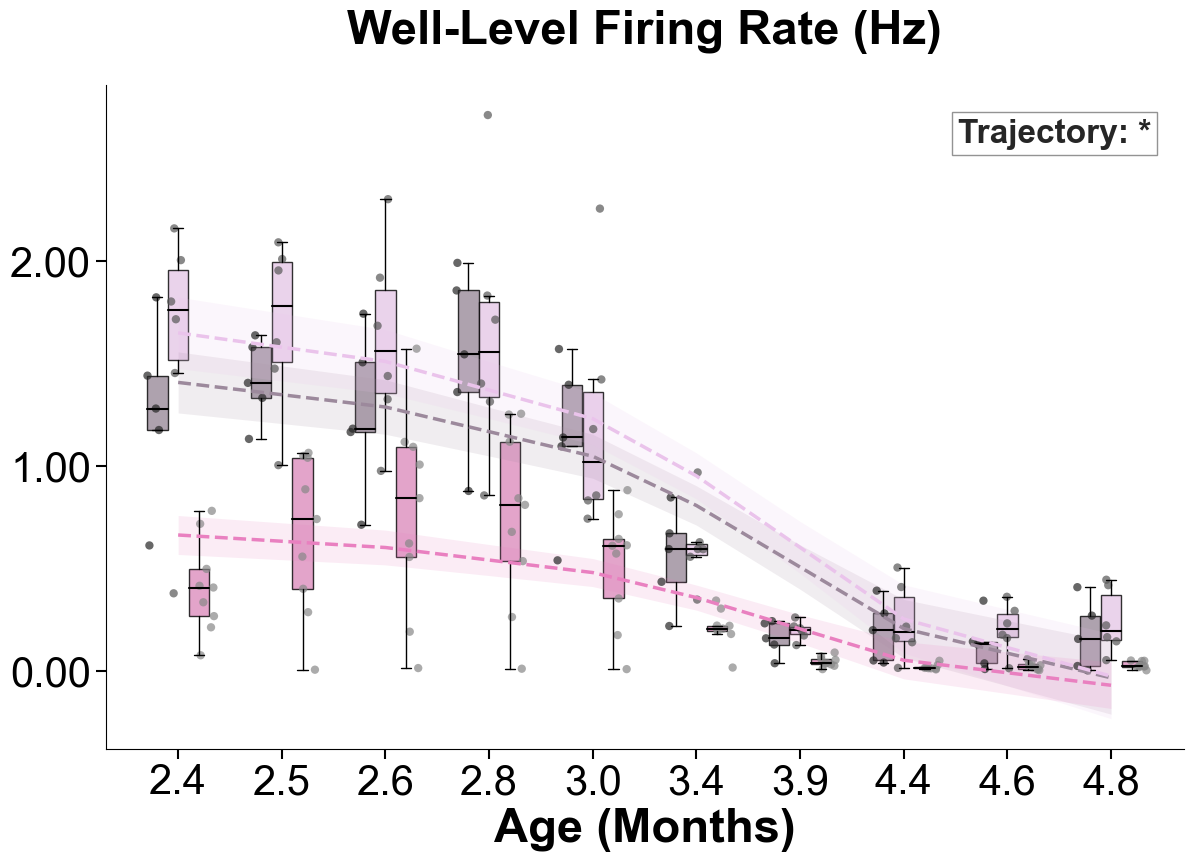

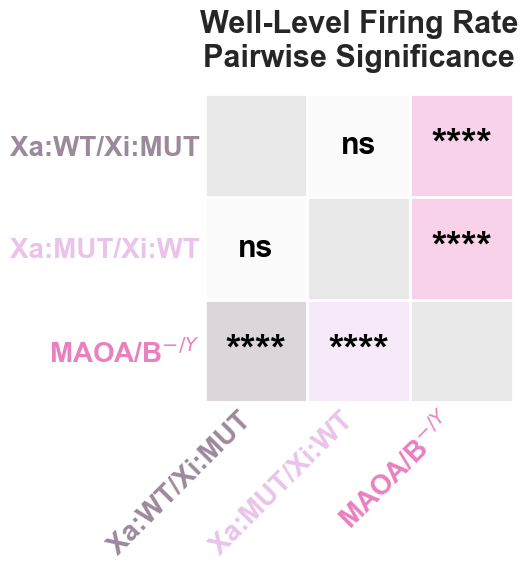

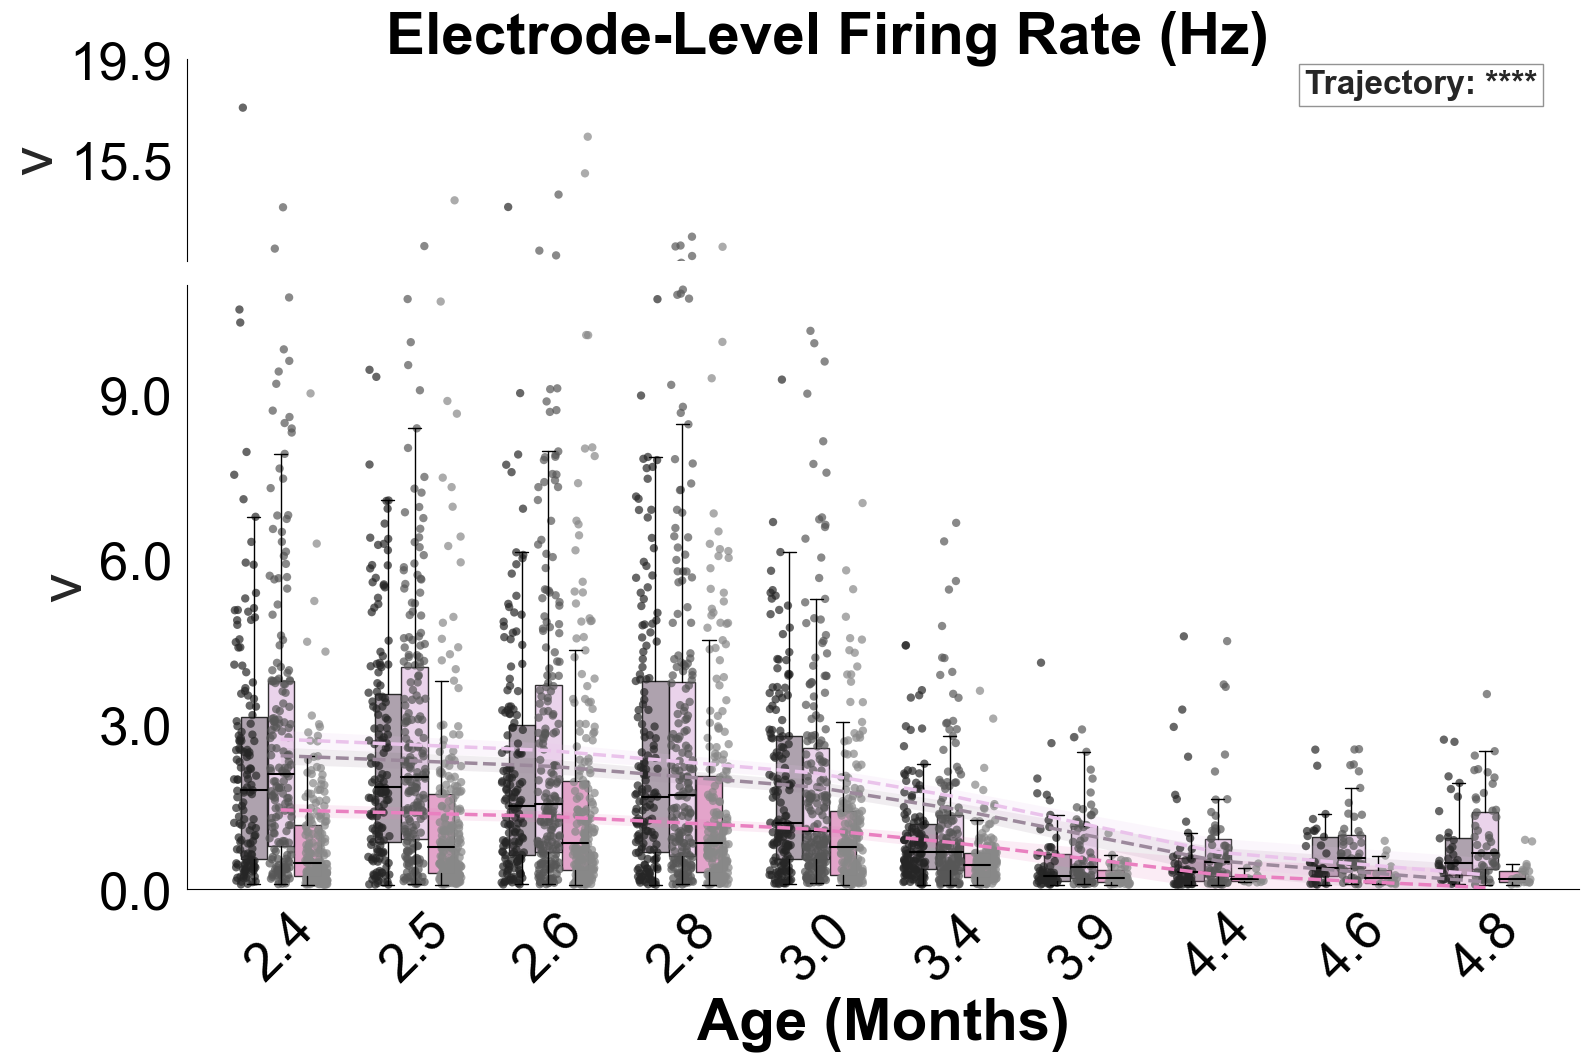

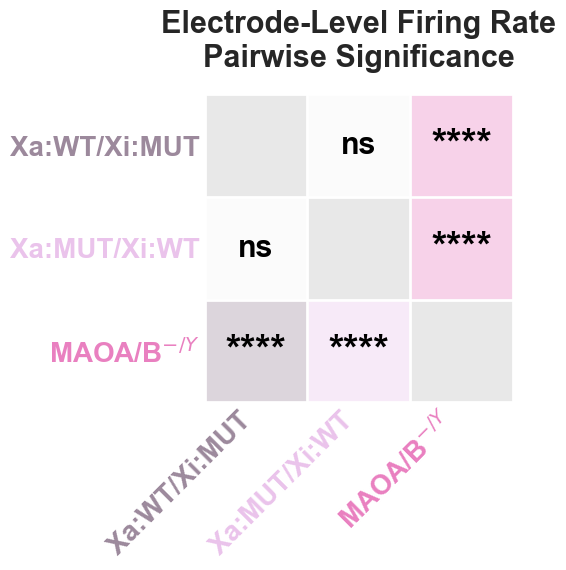


--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.56e-05 ****
        age 1.68e-70 ****
group x age   0.0132    *
Overall group differences (Holm):
        group1       group2    diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.364    3e-07 ****
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.294 7.87e-05 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.0692    0.371   ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                           ****                           ****                           ns
  2.5                           ****                            ***                           ns
  2.6                            ***                             ns                           ns
  2.8                            ***                             **                           ns
  3.0                             

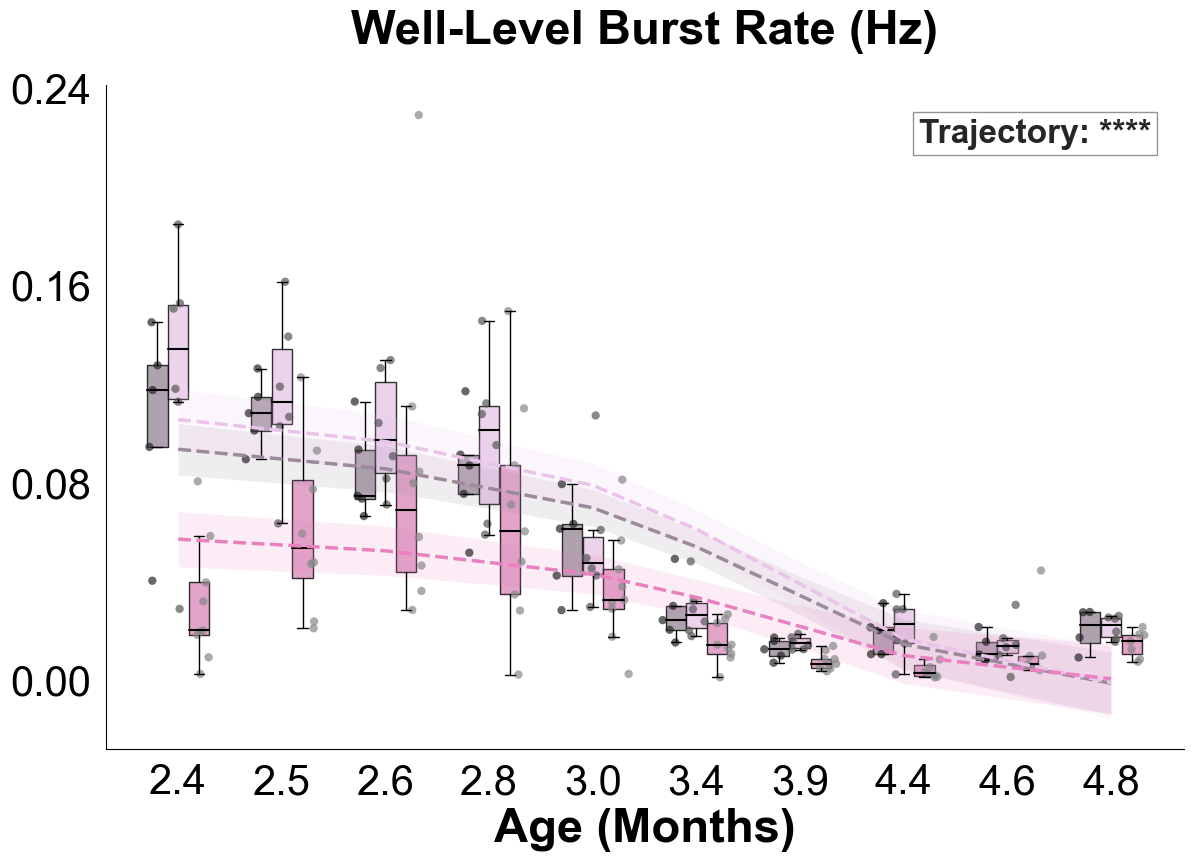

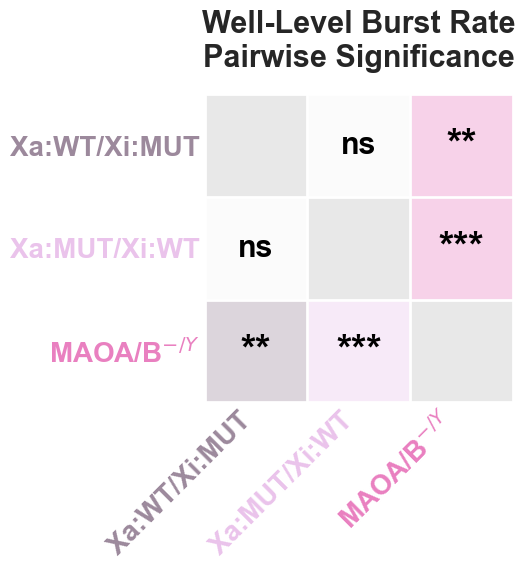

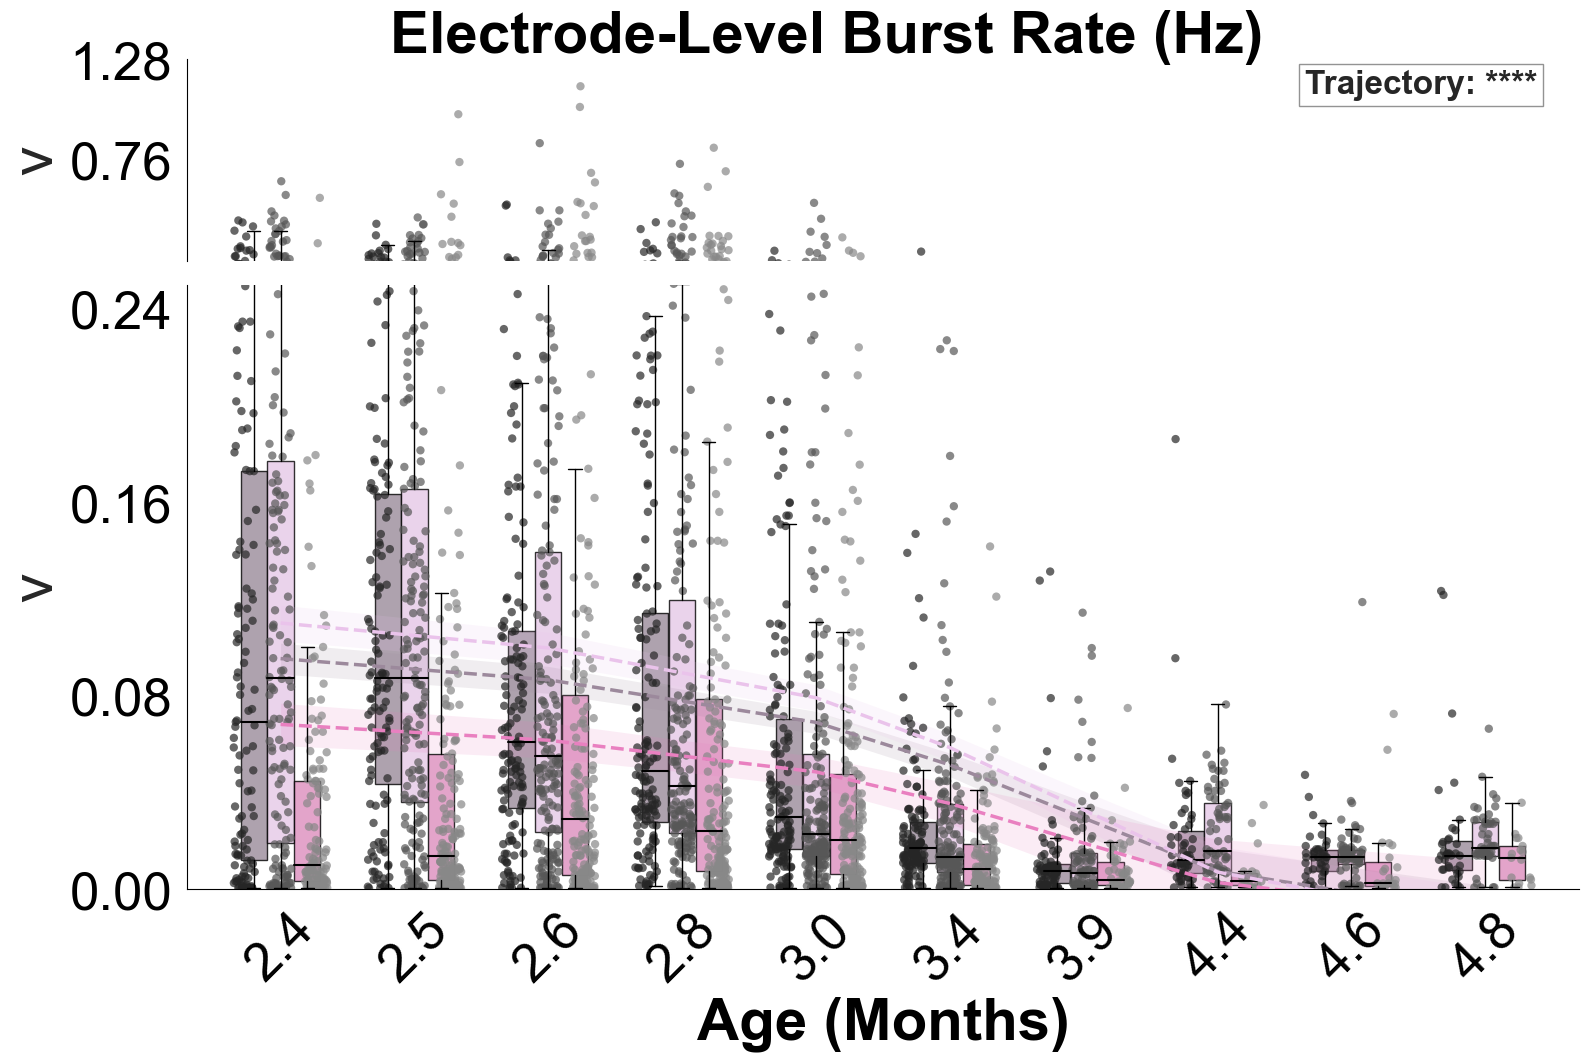

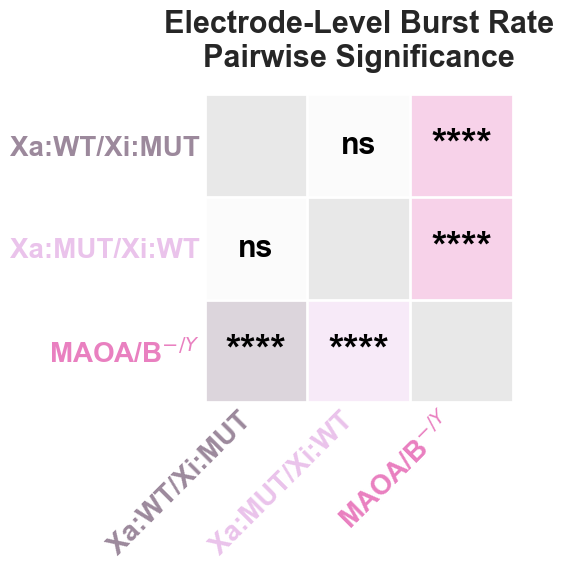


--- WELL-LEVEL BURST: mixed model, random intercept per well (n=192, wells=20) ---
       term        p  sig
      group  0.00232   **
        age 9.01e-48 ****
group x age 1.93e-05 ****
Overall group differences (Holm):
        group1       group2     diff    p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.0588 0.000694 ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.0507  0.00492  **
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.00803    0.655  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                           ****                           ****                           ns
  2.5                             **                              *                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                             ns                           ns
  3.0                             n

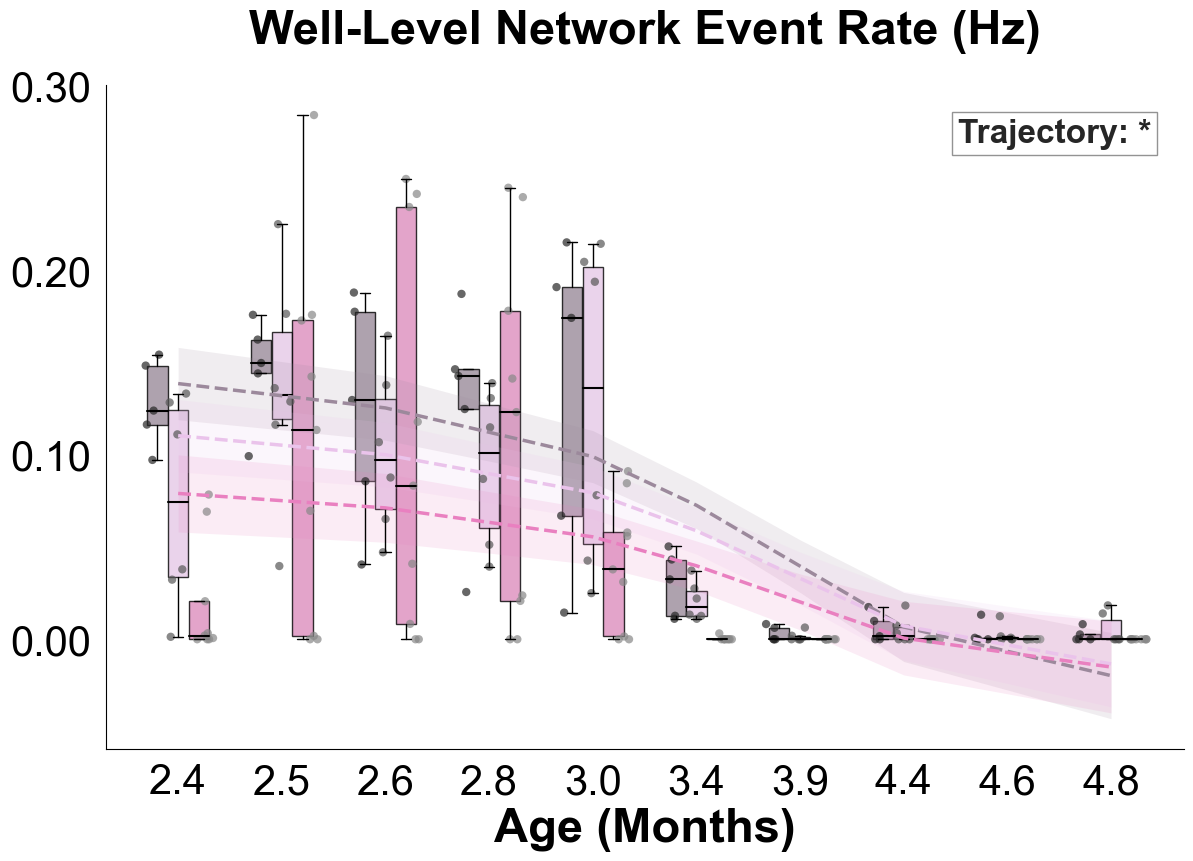

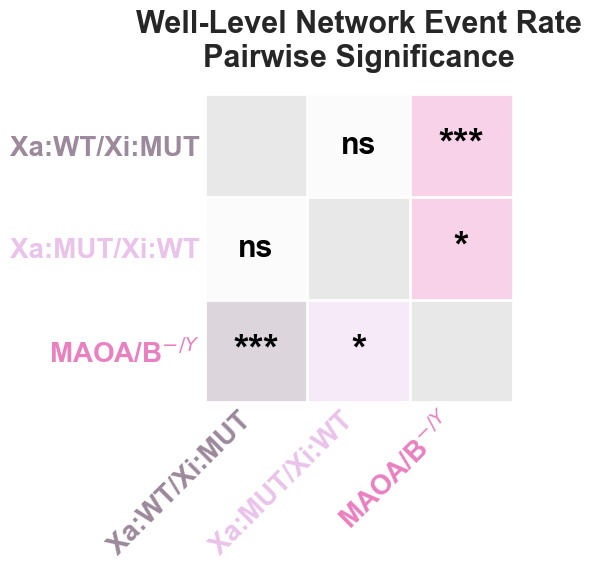


--- WELL-LEVEL NETWORK: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group  0.00332   **
        age 7.39e-41 ****
group x age   0.0369    *
Overall group differences (Holm):
        group1       group2   diff    p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0737   0.0111   *
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.101 0.000835 ***
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0276    0.359  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                              *                           ****                           ns
  2.5                             ns                             ns                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                             ns                           ns
  3.0                              *     

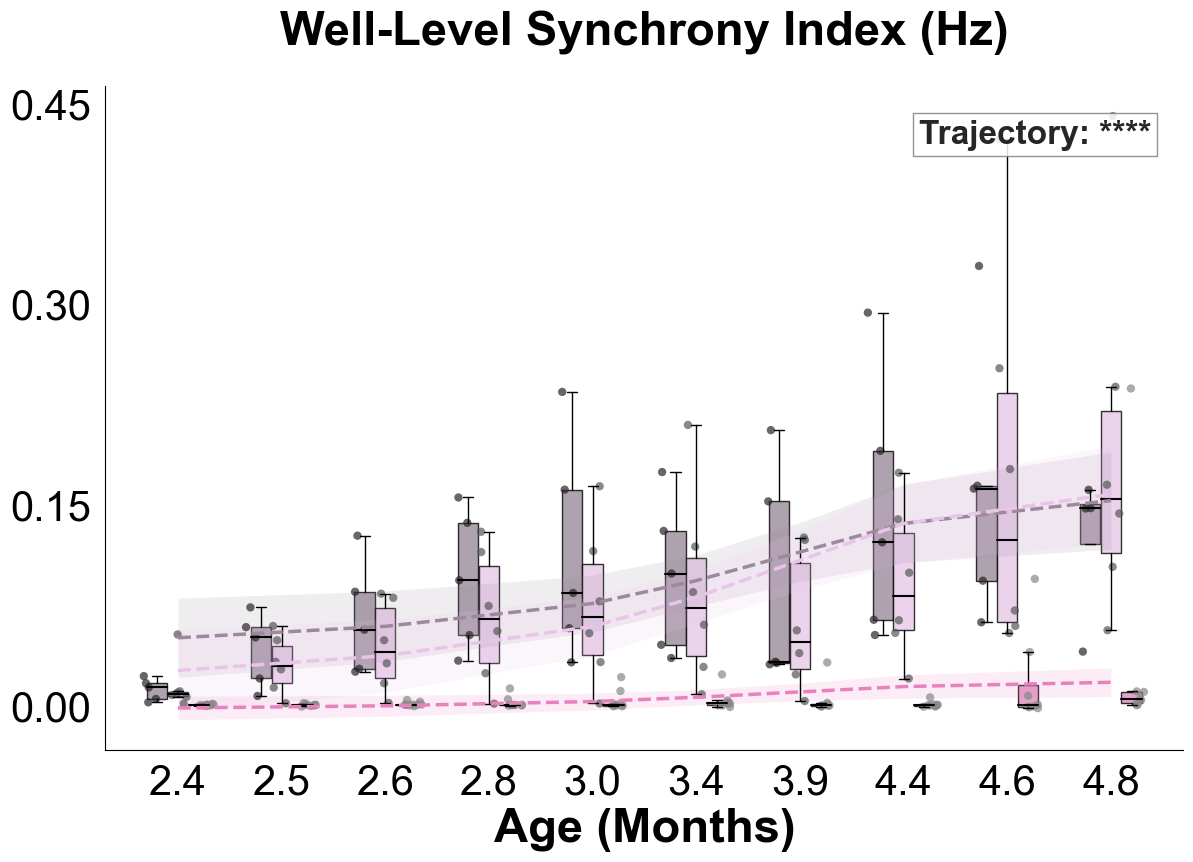

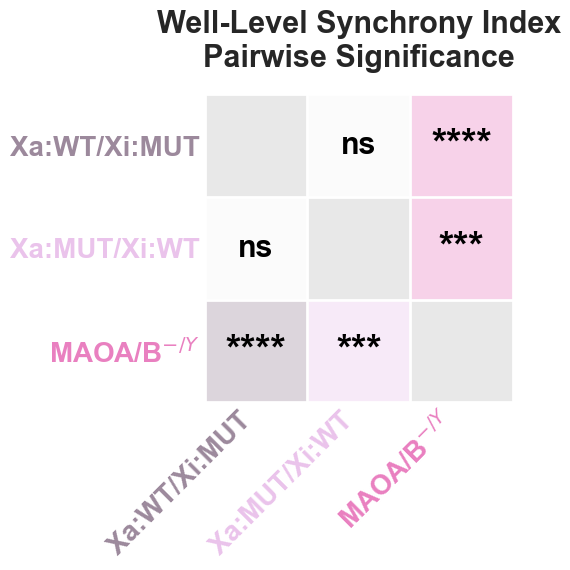


--- WELL-LEVEL SYNCHRONY: mixed model, random intercept per well (n=197, wells=20) ---
       term        p  sig
      group 0.000488  ***
        age 1.54e-12 ****
group x age 1.05e-06 ****
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0716 0.000479  ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.0868 6.68e-05 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0152    0.491   ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                             ns                             ns                           ns
  2.5                             ns                             ns                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                              *                           ns
  3.0                             n

In [11]:
exp1_stats = run_mea_analysis_for_figure(
    exp1_df,
    experiment="Exp1", unit="months",
    palette=MAOA_FIGURE_PALETTE,
    save_dir=TRAJ_DIR
)

## Bar plots — pooled over the good-data window


--- GENERATING GROUPED PLOTS FOR FIRING ---


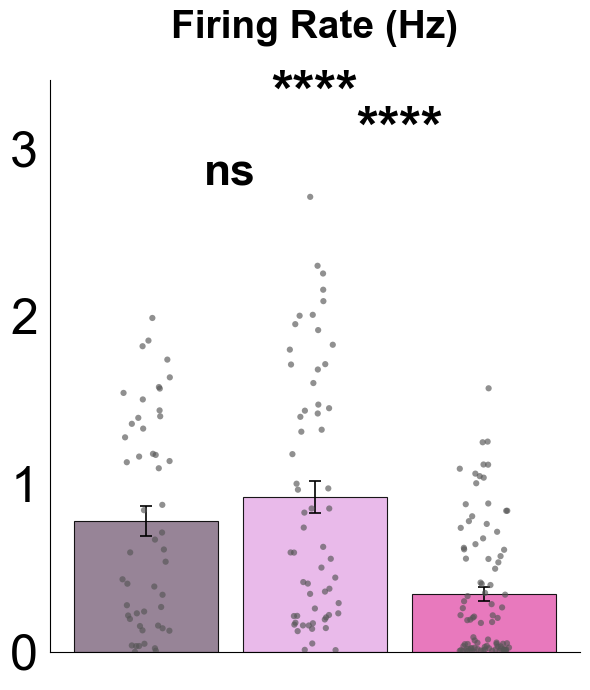

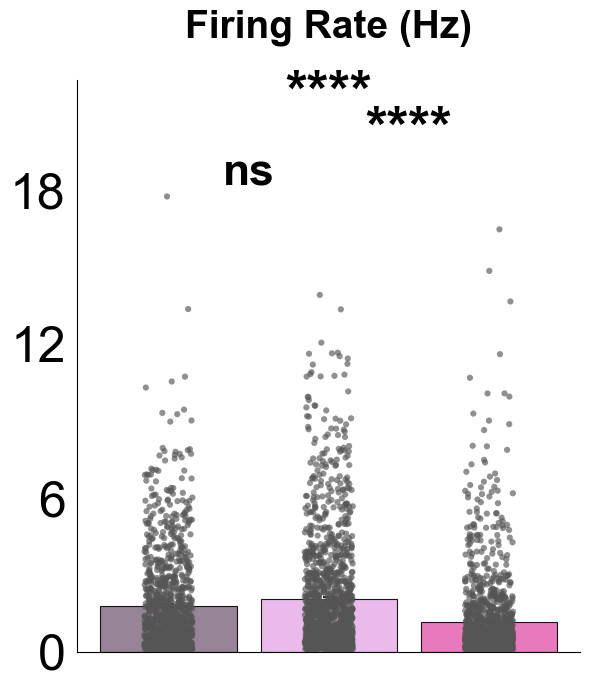


--- WELL-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.56e-05 ****
        age 1.68e-70 ****
group x age   0.0132    *
Overall group differences (Holm):
        group1       group2    diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.364    3e-07 ****
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.294 7.87e-05 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.0692    0.371   ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                           ****                           ****                           ns
  2.5                           ****                            ***                           ns
  2.6                            ***                             ns                           ns
  2.8                            ***                             **                           ns
  3.0                  

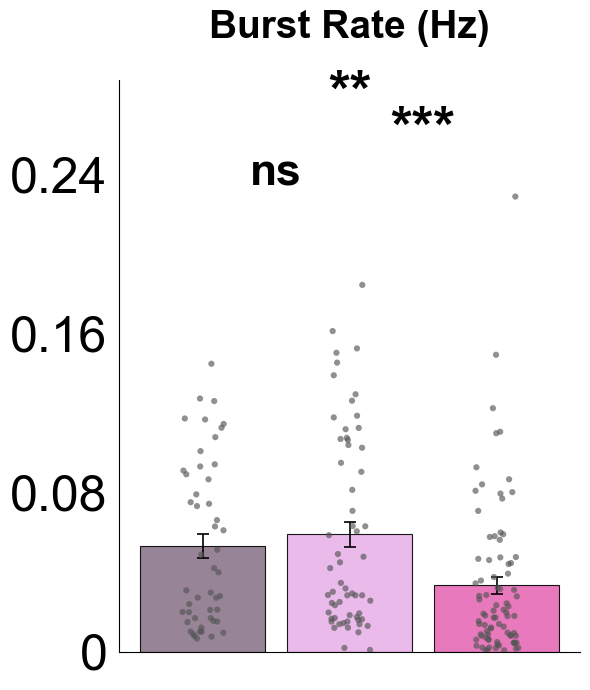

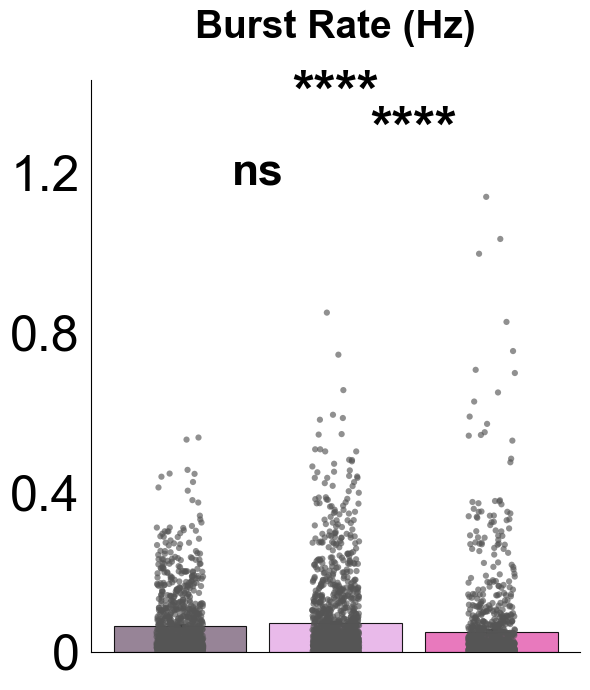


--- WELL-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=192, wells=20) ---
       term        p  sig
      group  0.00232   **
        age 9.01e-48 ****
group x age 1.93e-05 ****
Overall group differences (Holm):
        group1       group2     diff    p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.0588 0.000694 ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.0507  0.00492  **
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.00803    0.655  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                           ****                           ****                           ns
  2.5                             **                              *                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                             ns                           ns
  3.0                   

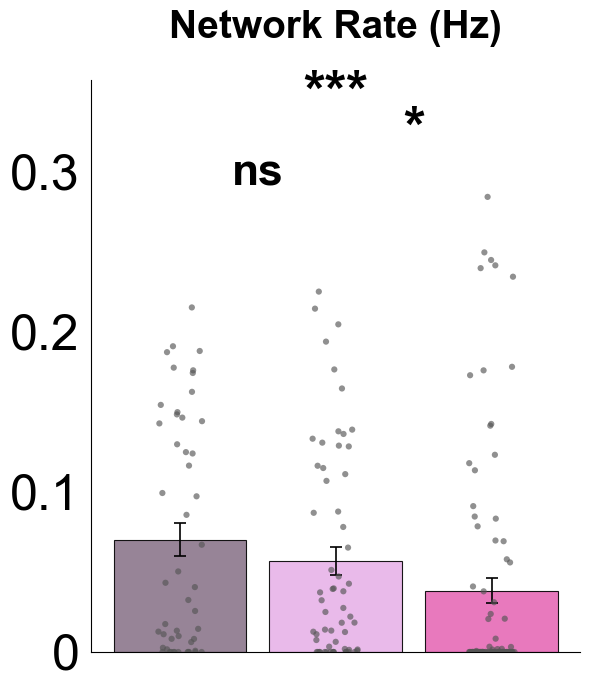


--- WELL-LEVEL NETWORK (BAR PLOT): mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group  0.00332   **
        age 7.39e-41 ****
group x age   0.0369    *
Overall group differences (Holm):
        group1       group2   diff    p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0737   0.0111   *
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.101 0.000835 ***
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0276    0.359  ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                              *                           ****                           ns
  2.5                             ns                             ns                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                             ns                           ns
  3.0                         

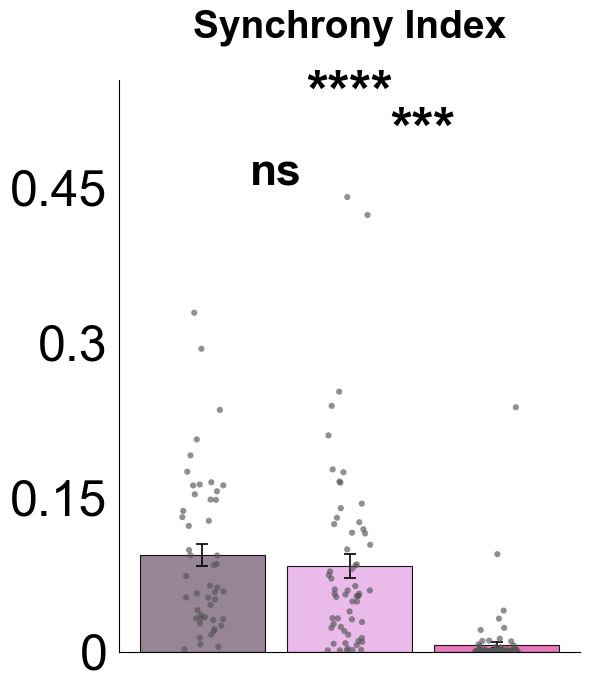


--- WELL-LEVEL SYNCHRONY (BAR PLOT): mixed model, random intercept per well (n=197, wells=20) ---
       term        p  sig
      group 0.000488  ***
        age 1.54e-12 ****
group x age 1.05e-06 ****
Overall group differences (Holm):
        group1       group2   diff    p-adj  sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT 0.0716 0.000479  ***
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT 0.0868 6.68e-05 ****
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT 0.0152    0.491   ns
Per-age group differences (Holm across all ages x pairs):
 Time MAOA/B$^{-/Y}$ vs Xa:MUT/Xi:WT MAOA/B$^{-/Y}$ vs Xa:WT/Xi:MUT Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT
  2.4                             ns                             ns                           ns
  2.5                             ns                             ns                           ns
  2.6                             ns                             ns                           ns
  2.8                             ns                              *                           ns
  3.0                   

In [12]:
run_grouped_analysis(exp1_df, "Exp1", save_dir=TRAJ_DIR)

## Bar plots — oldest good timepoint only


--- GENERATING GROUPED PLOTS FOR FIRING ---


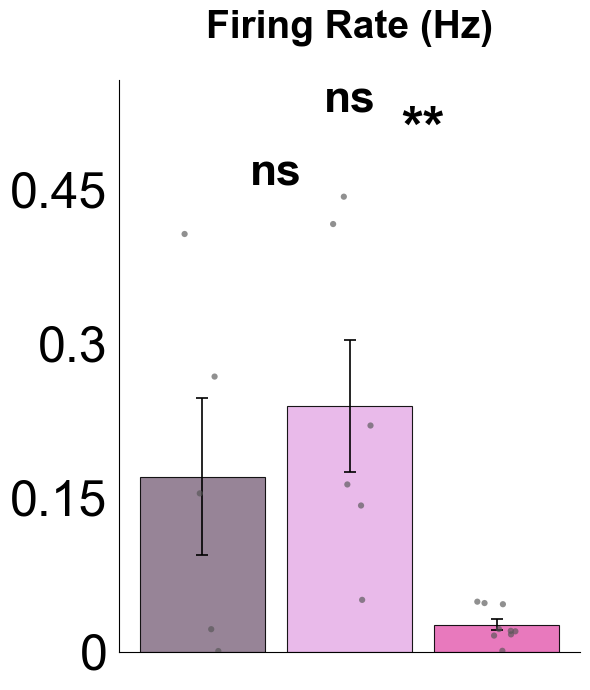

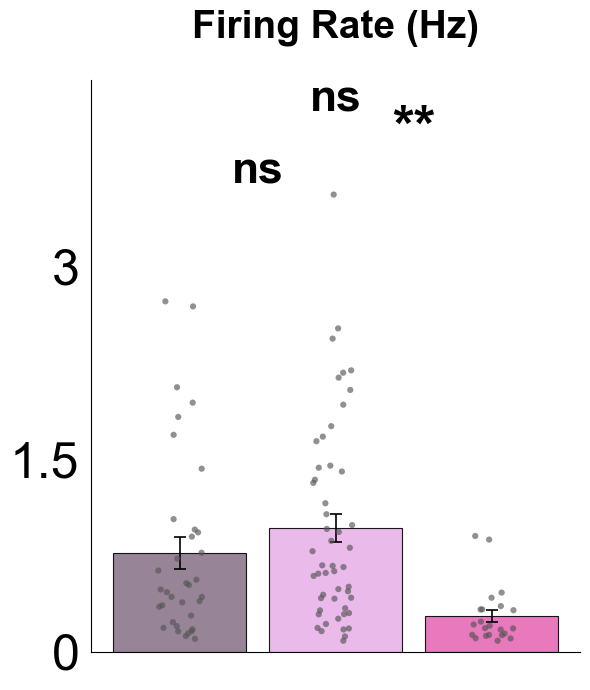


--- WELL-LEVEL FIRING (BAR PLOT): OLS, one observation per well (n=20, wells=20) ---
 term       p sig
group 0.00216  **
Overall group differences (Holm):
        group1       group2   diff   p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT  0.286 0.00143  **
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.173  0.0874  ns
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.113   0.224  ns

--- ELECTRODE-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=108, wells=18) ---
 term      p sig
group 0.0101   *
Overall group differences (Holm):
        group1       group2   diff   p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT  0.301 0.00682  **
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.195   0.118  ns
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.106   0.142  ns

--- GENERATING GROUPED PLOTS FOR BURST ---


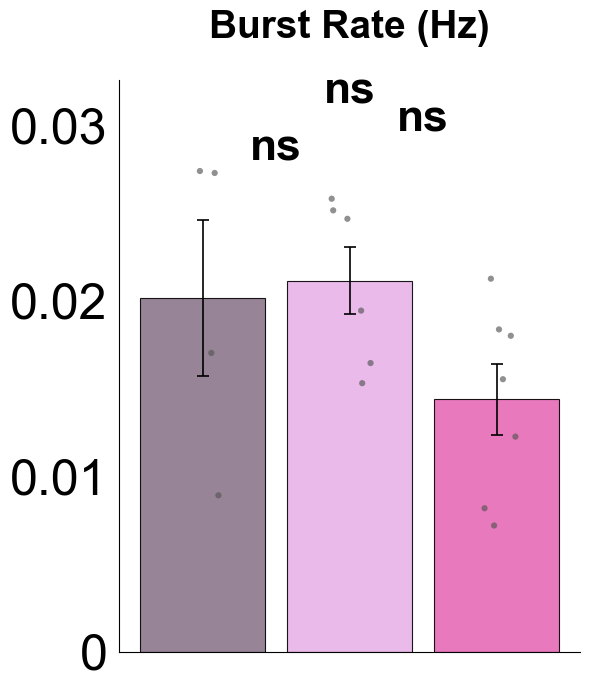

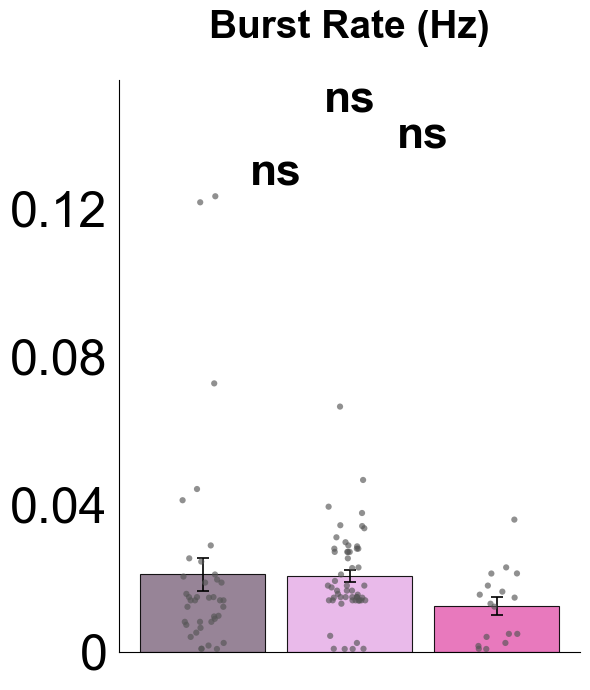


--- WELL-LEVEL BURST (BAR PLOT): OLS, one observation per well (n=17, wells=17) ---
 term     p sig
group 0.116  ns
Overall group differences (Holm):
        group1       group2     diff  p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.0256  0.188  ns
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT   0.0157  0.647  ns
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.00994  0.647  ns

--- ELECTRODE-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=110, wells=17) ---
 term     p sig
group 0.207  ns
Overall group differences (Holm):
        group1       group2    diff  p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT  0.0302    0.3  ns
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.0175  0.585  ns
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.0127  0.585  ns

--- GENERATING GROUPED PLOTS FOR NETWORK ---


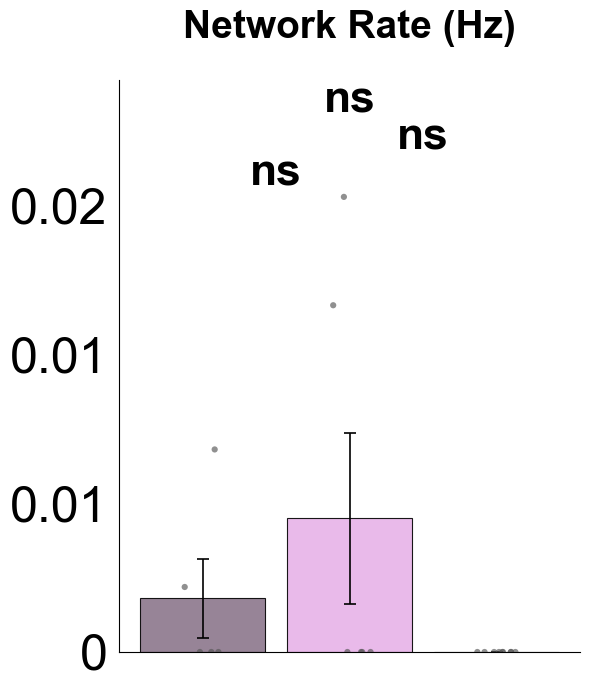


--- WELL-LEVEL NETWORK (BAR PLOT): OLS, one observation per well (n=20, wells=20) ---
 term    p sig
group 0.15  ns
Overall group differences (Holm):
        group1       group2    diff  p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT  0.0373  0.268  ns
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.0258  0.524  ns
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.0114  0.645  ns

--- GENERATING GROUPED PLOTS FOR SYNCHRONY ---


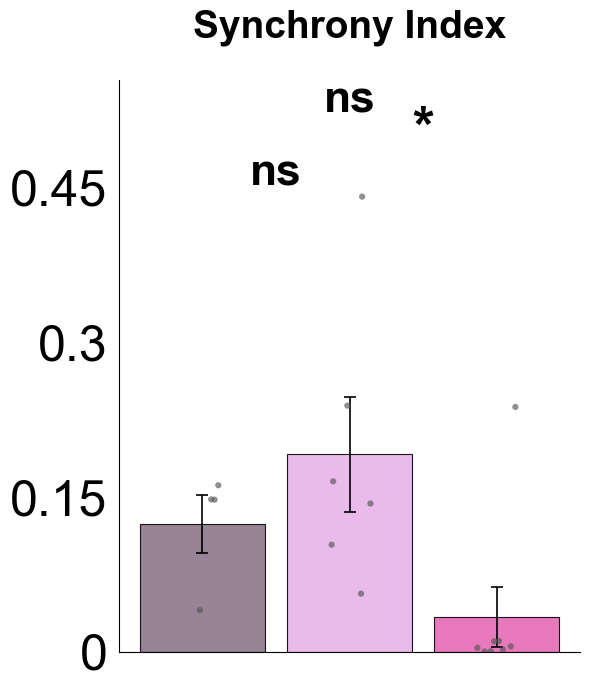


--- WELL-LEVEL SYNCHRONY (BAR PLOT): OLS, one observation per well (n=18, wells=18) ---
 term      p sig
group 0.0338   *
Overall group differences (Holm):
        group1       group2    diff  p-adj sig
MAOA/B$^{-/Y}$ Xa:MUT/Xi:WT   0.133 0.0452   *
MAOA/B$^{-/Y}$ Xa:WT/Xi:MUT  0.0559  0.456  ns
  Xa:MUT/Xi:WT Xa:WT/Xi:MUT -0.0768  0.456  ns


In [13]:
run_grouped_analysis(oldest_df, "Exp1", save_dir=OLDEST_DIR)

# Supplementary — by clone


FEATURE: FIRING


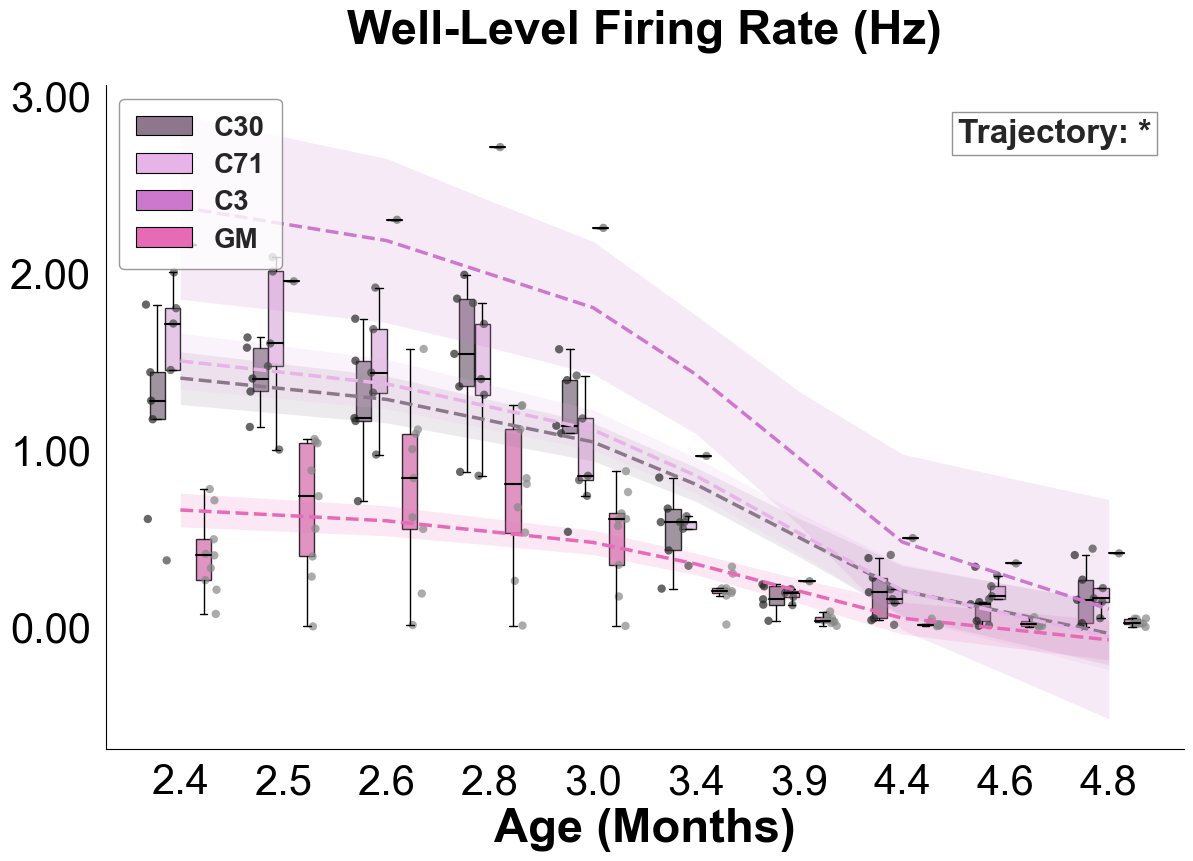

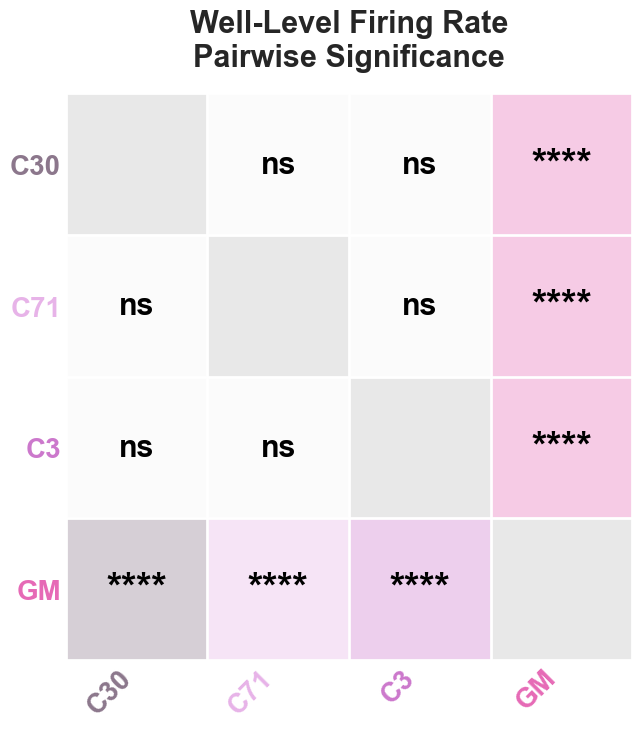

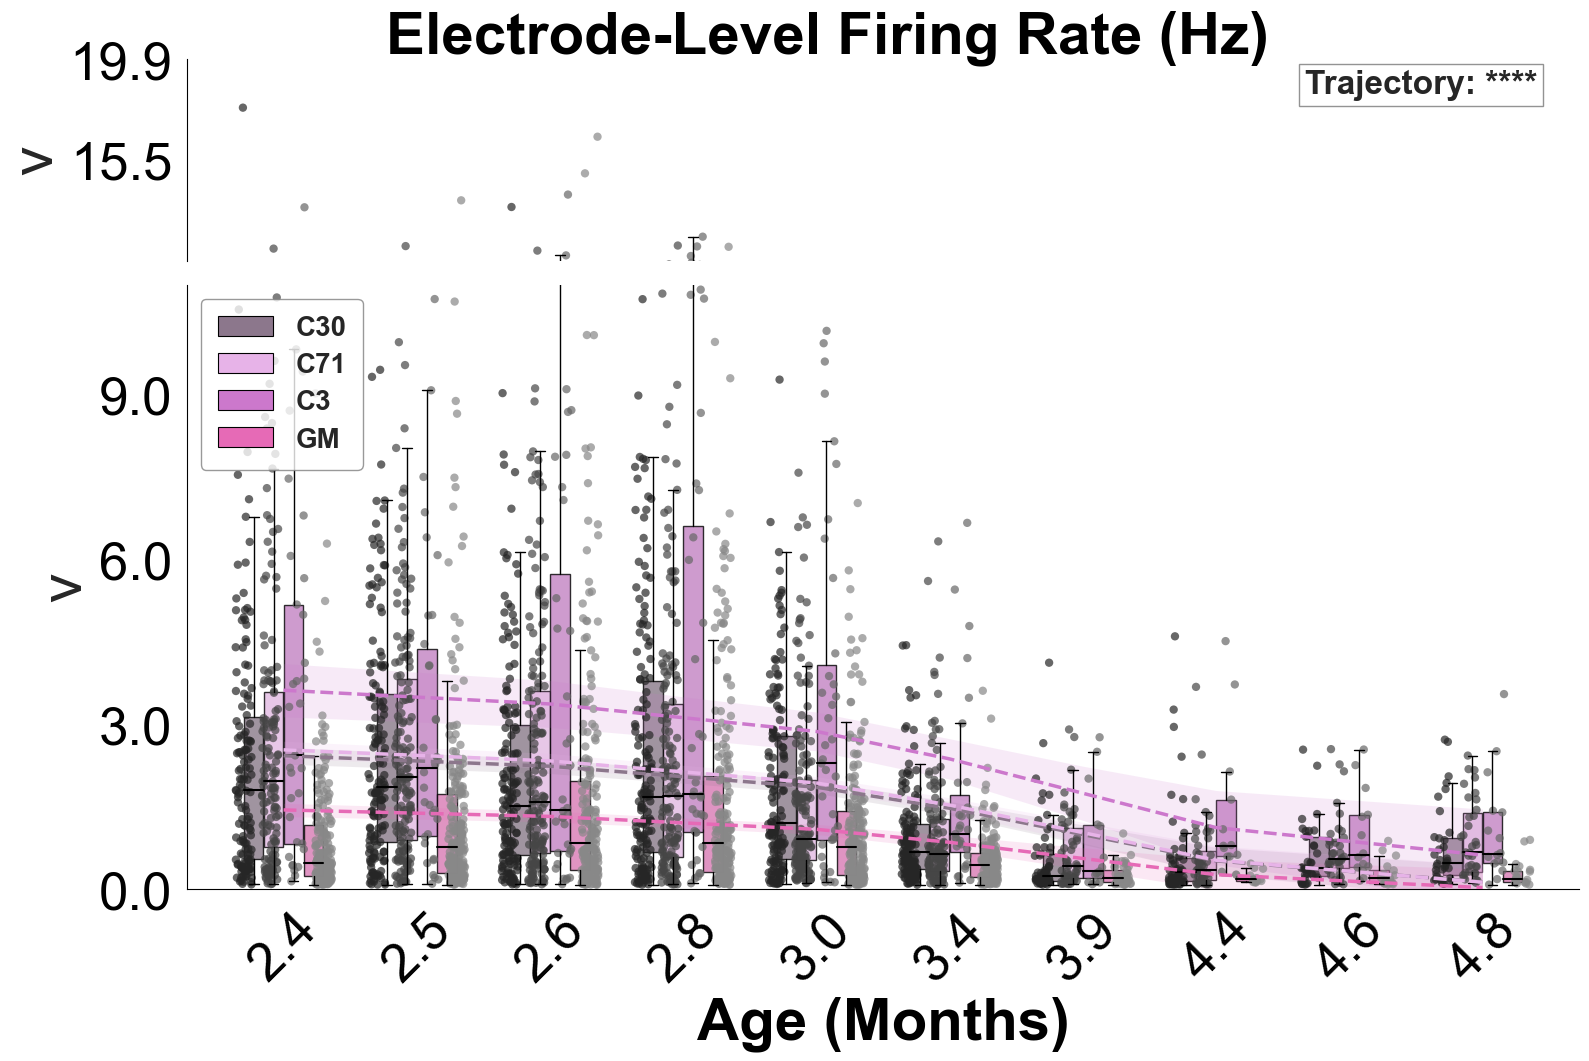

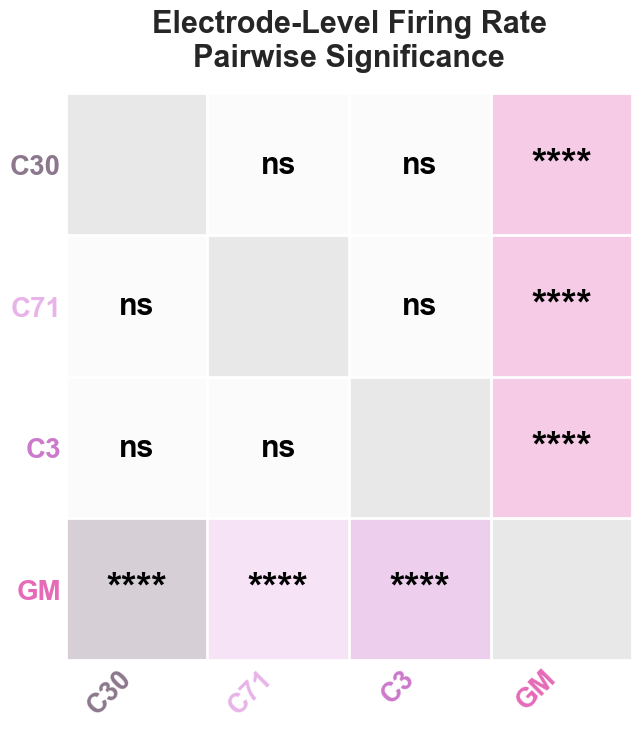


--- WELL-LEVEL FIRING: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.72e-05 ****
        age 1.68e-70 ****
group x age   0.0322    *
Overall group differences (Holm):
group1 group2   diff    p-adj  sig
    C3    C30 -0.262    0.156   ns
    C3    C71 -0.229    0.181   ns
    C3     GM -0.558 8.55e-05 ****
   C30    C71 0.0336    0.656   ns
   C30     GM -0.296 5.04e-05 ****
   C71     GM -0.329 5.28e-06 ****
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns      ***         ns      ****      ****
  2.5        ns        ns       ns         ns       ***      ****
  2.6        ns        ns        *         ns        ns        **
  2.8        ns        ns       **         ns        **        **
  3.0        ns        ns       **         ns        **        ns
  3.4        ns        ns       ns         ns        ns        ns
  3.9       

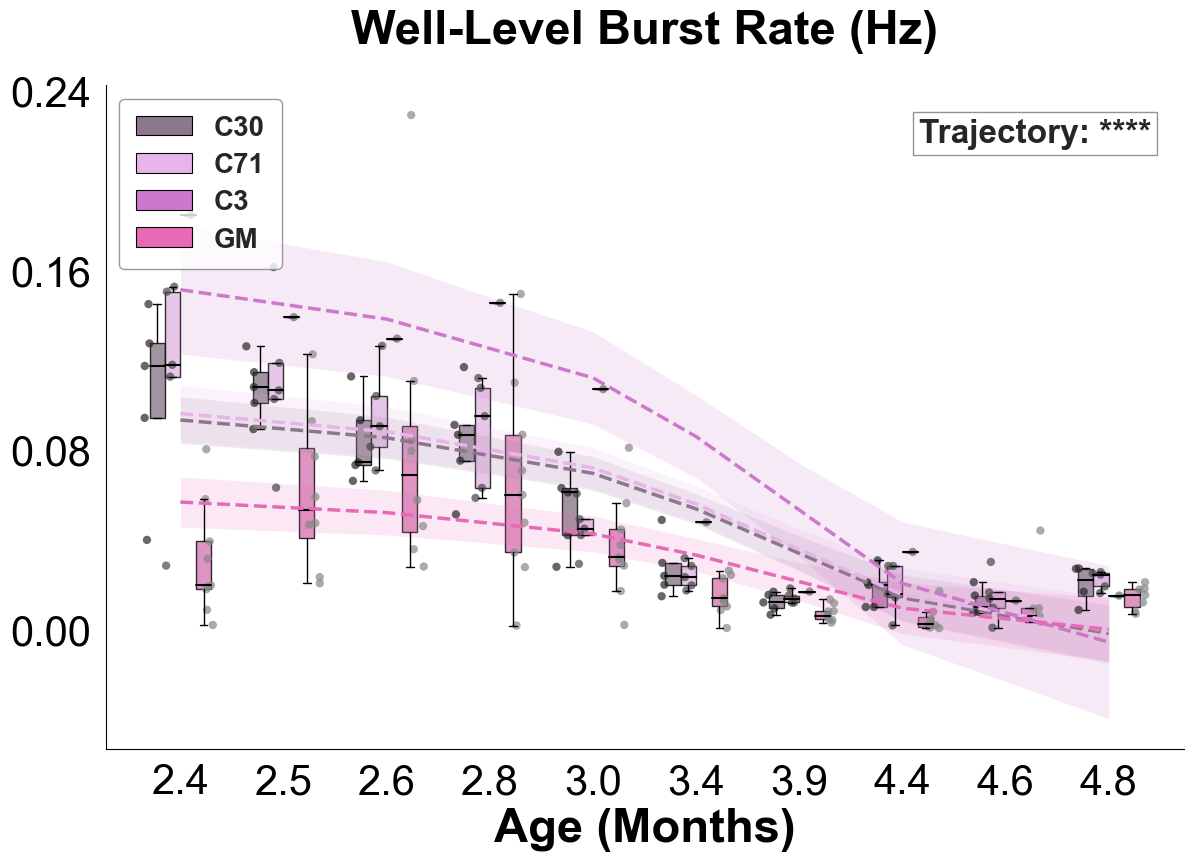

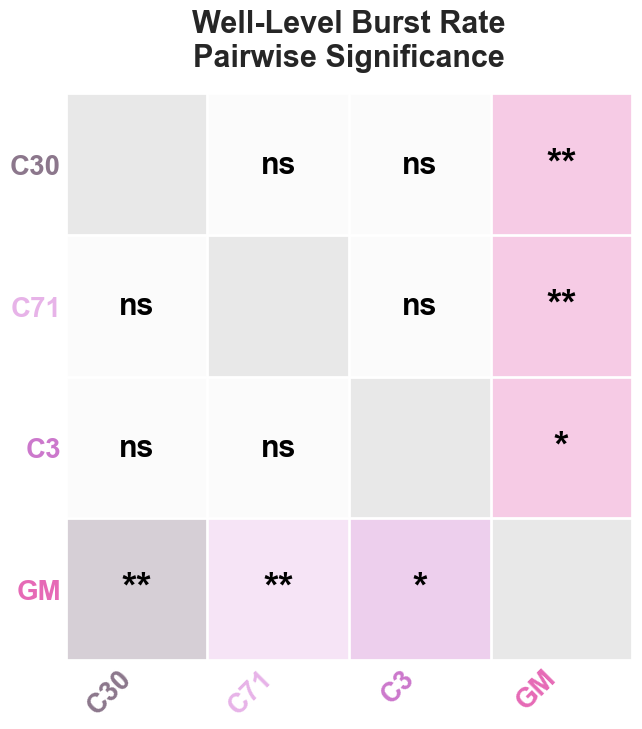

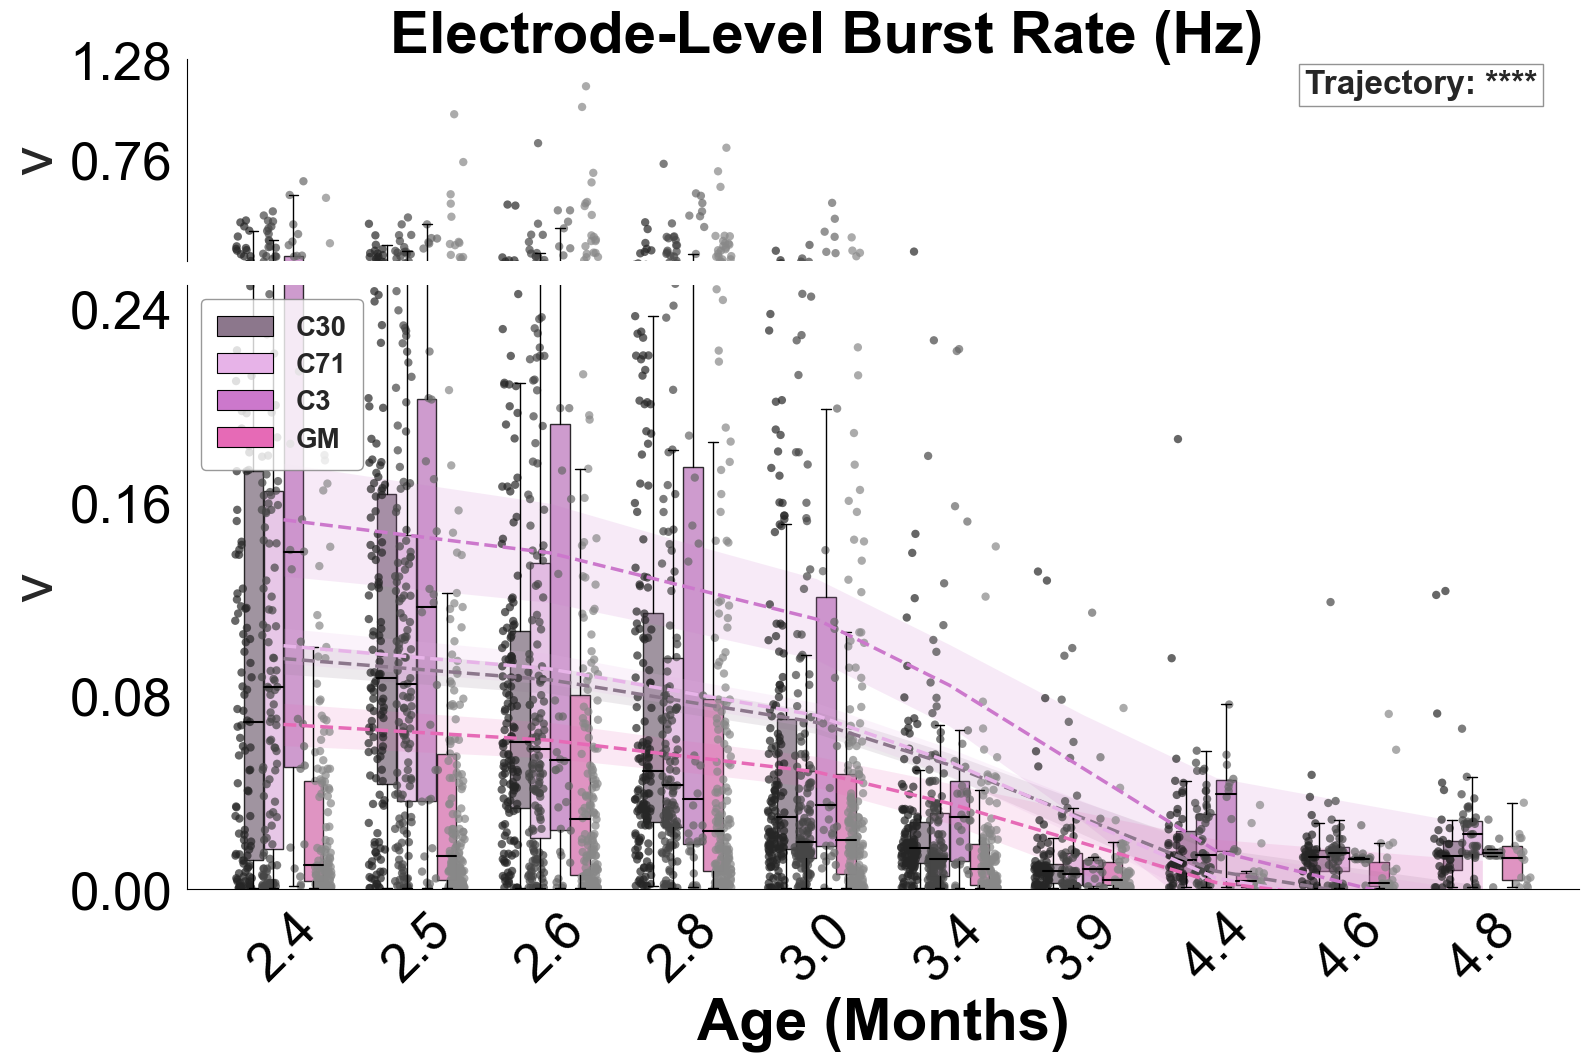

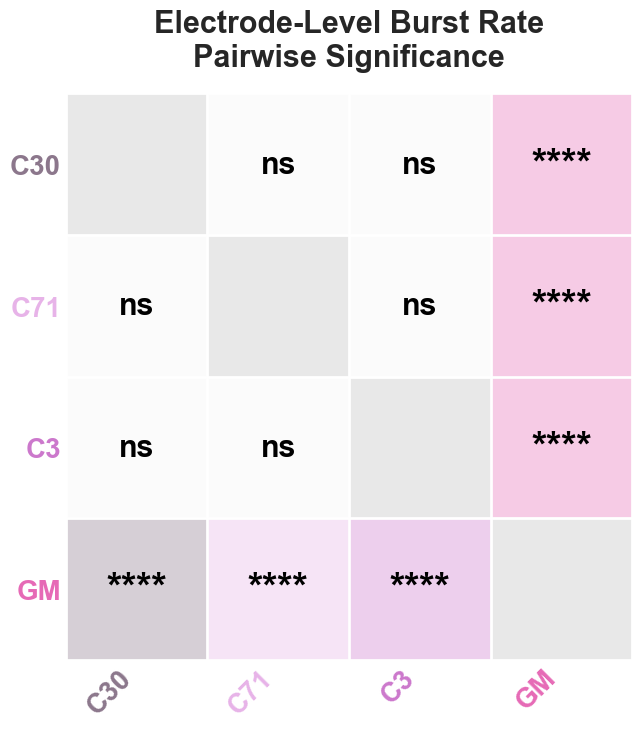


--- WELL-LEVEL BURST: mixed model, random intercept per well (n=192, wells=20) ---
       term        p  sig
      group  0.00368   **
        age 7.64e-48 ****
group x age 7.28e-05 ****
Overall group differences (Holm):
group1 group2    diff   p-adj sig
    C3    C30 -0.0405   0.633  ns
    C3    C71 -0.0385   0.633  ns
    C3     GM -0.0915  0.0152   *
   C30    C71 0.00204    0.91  ns
   C30     GM -0.0509 0.00822  **
   C71     GM  -0.053 0.00621  **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns     ****         ns      ****      ****
  2.5        ns        ns       ns         ns         *         *
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        ns        ns
  3.0        ns        ns       ns         ns        ns        ns
  3.4        ns        ns       ns         ns        ns        ns
  3.9        ns     

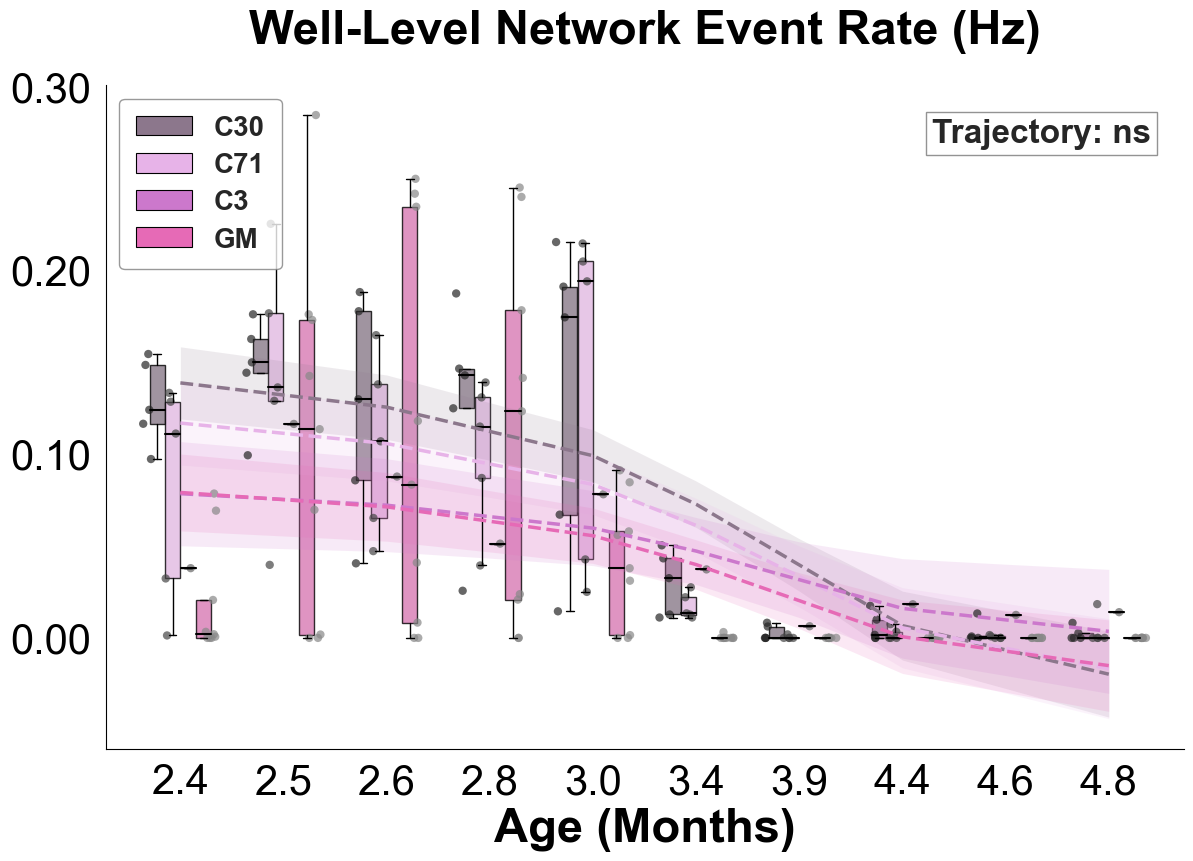

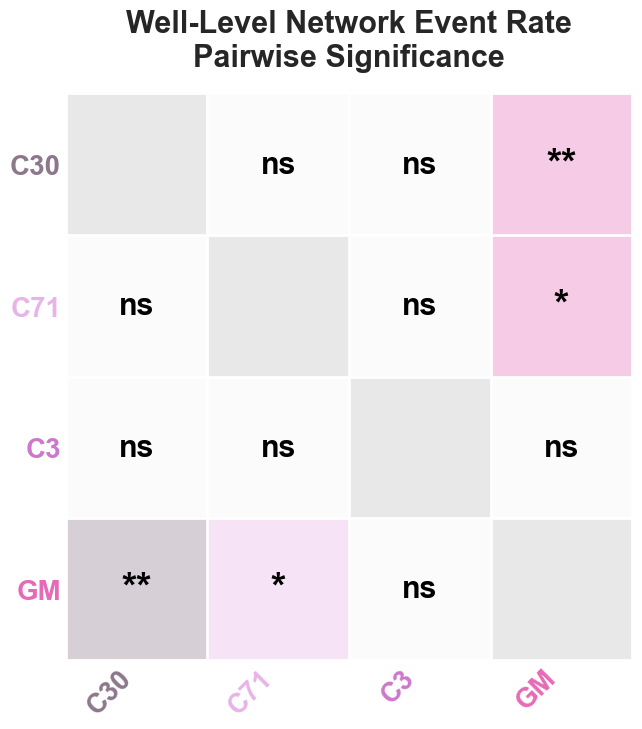


--- WELL-LEVEL NETWORK: mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group  0.00967   **
        age 7.39e-41 ****
group x age    0.103   ns
Overall group differences (Holm):
group1 group2    diff   p-adj sig
    C3    C30  0.0297       1  ns
    C3    C71  0.0025       1  ns
    C3     GM -0.0716    0.76  ns
   C30    C71 -0.0272       1  ns
   C30     GM  -0.101 0.00167  **
   C71     GM -0.0741  0.0393   *
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns       ns         ns      ****        ns
  2.5        ns        ns       ns         ns        ns        ns
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        ns        ns
  3.0        ns        ns       ns         ns         *         *
  3.4        ns        ns       ns         ns        ns        ns
  3.9        ns   

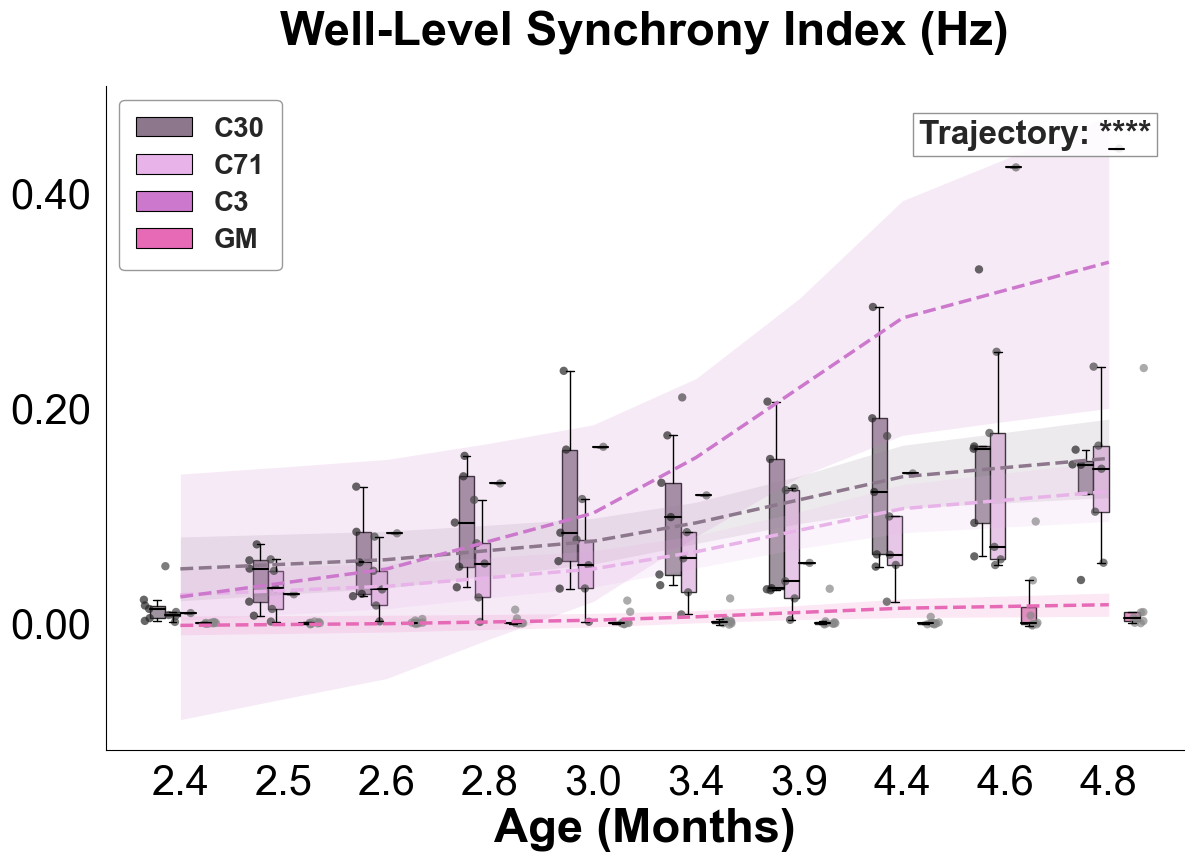

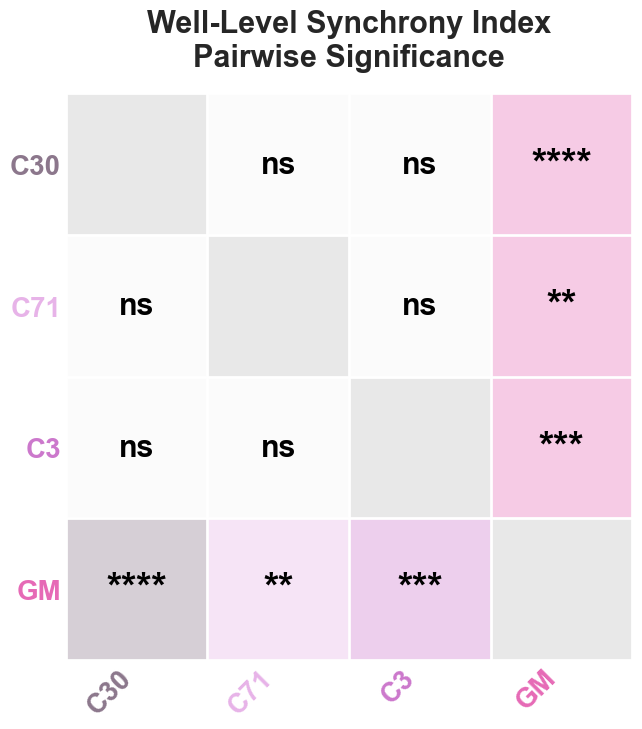


--- WELL-LEVEL SYNCHRONY: mixed model, random intercept per well (n=197, wells=20) ---
       term        p  sig
      group  0.00022  ***
        age 1.65e-12 ****
group x age 1.72e-20 ****
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30 -0.0525    0.313   ns
    C3    C71 -0.0801   0.0913   ns
    C3     GM   -0.14  0.00053  ***
   C30    C71 -0.0277    0.313   ns
   C30     GM -0.0872 1.32e-05 ****
   C71     GM -0.0596  0.00482   **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns       ns         ns        ns        ns
  2.5        ns        ns       ns         ns        ns        ns
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        **        ns
  3.0        ns        ns        *         ns       ***        ns
  3.4        ns        ns       ns         ns        **        ns
  

{'firing': {'Well-Level': {'data':     group  time_val plate_name   well_id       val         y
   0     C30       2.4      MAOA2  MAOA2_A2  1.439121  1.199634
   1      GM       2.4      MAOA2  MAOA2_A3  0.405203  0.636555
   2     C71       2.4      MAOA2  MAOA2_B1  2.002933  1.415250
   3     C30       2.4      MAOA2  MAOA2_B2  1.821286  1.349550
   4      GM       2.4      MAOA2  MAOA2_B3  0.779313  0.882787
   ..    ...       ...        ...       ...       ...       ...
   195   C71       4.8      MAOA1  MAOA1_B1  0.163073  0.403823
   196   C30       4.8      MAOA1  MAOA1_B2  0.406833  0.637834
   197    GM       4.8      MAOA1  MAOA1_B3  0.017143  0.130933
   198   C71       4.8      MAOA1  MAOA1_C1  0.443140  0.665688
   199    GM       4.8      MAOA1  MAOA1_C3  0.001166  0.034150
   
   [200 rows x 6 columns],
   'lrt':           term             p
   0        group  5.720481e-05
   1          age  1.677741e-70
   2  group x age  3.217527e-02,
   'overall':   group1 group2    

In [14]:
run_mea_analysis_by_clone(exp1_df, experiment="Exp1", unit="months", save_dir=f"{TRAJ_DIR}/supplementary")


--- GENERATING CLONE PLOTS FOR FIRING ---


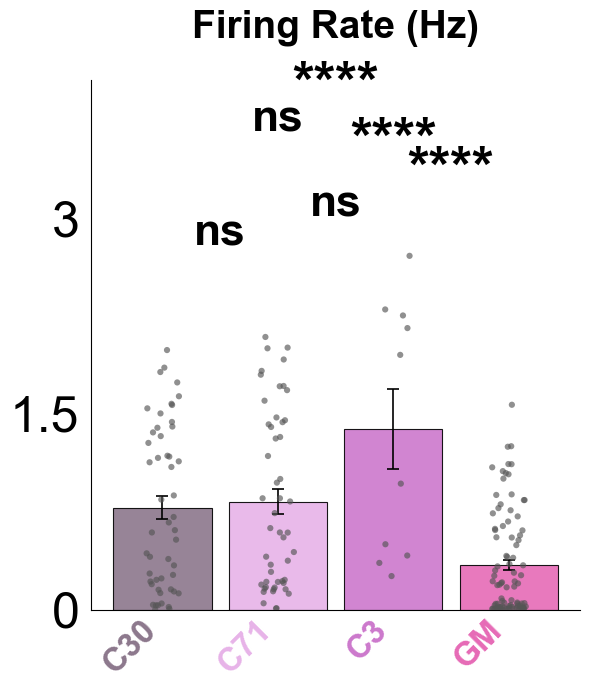

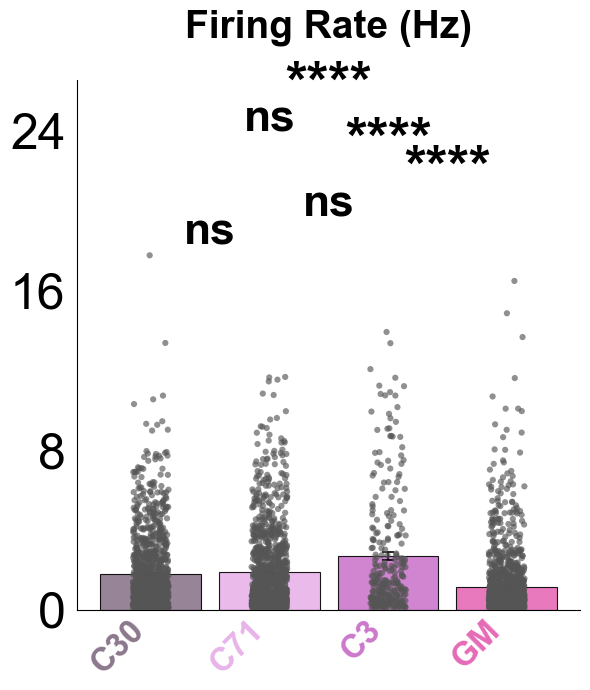


--- WELL-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group 5.72e-05 ****
        age 1.68e-70 ****
group x age   0.0322    *
Overall group differences (Holm):
group1 group2   diff    p-adj  sig
    C3    C30 -0.262    0.156   ns
    C3    C71 -0.229    0.181   ns
    C3     GM -0.558 8.55e-05 ****
   C30    C71 0.0336    0.656   ns
   C30     GM -0.296 5.04e-05 ****
   C71     GM -0.329 5.28e-06 ****
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns      ***         ns      ****      ****
  2.5        ns        ns       ns         ns       ***      ****
  2.6        ns        ns        *         ns        ns        **
  2.8        ns        ns       **         ns        **        **
  3.0        ns        ns       **         ns        **        ns
  3.4        ns        ns       ns         ns        ns        ns
 

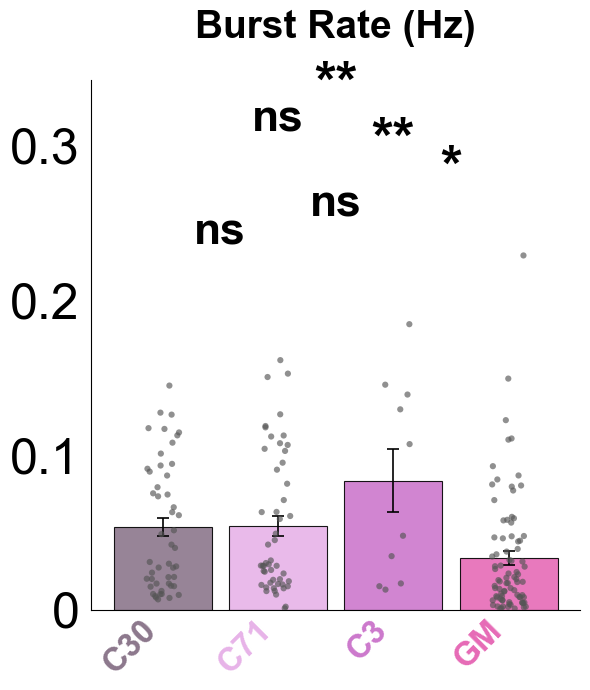

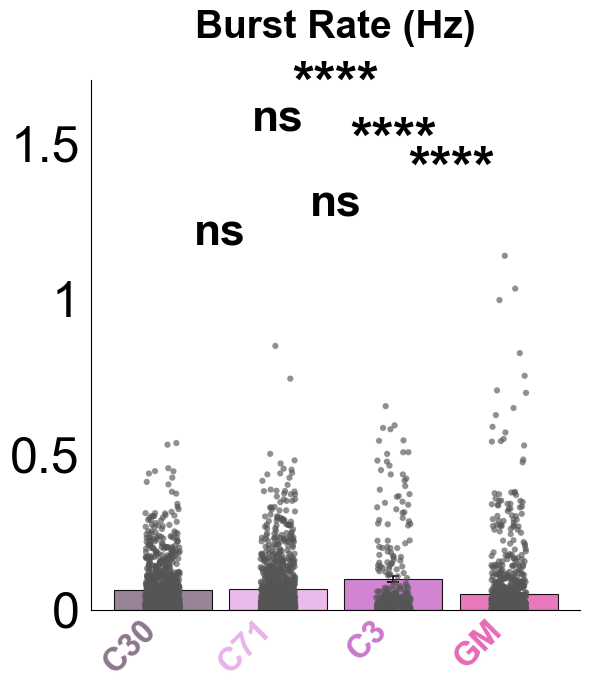


--- WELL-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=192, wells=20) ---
       term        p  sig
      group  0.00368   **
        age 7.64e-48 ****
group x age 7.28e-05 ****
Overall group differences (Holm):
group1 group2    diff   p-adj sig
    C3    C30 -0.0405   0.633  ns
    C3    C71 -0.0385   0.633  ns
    C3     GM -0.0915  0.0152   *
   C30    C71 0.00204    0.91  ns
   C30     GM -0.0509 0.00822  **
   C71     GM  -0.053 0.00621  **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns     ****         ns      ****      ****
  2.5        ns        ns       ns         ns         *         *
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        ns        ns
  3.0        ns        ns       ns         ns        ns        ns
  3.4        ns        ns       ns         ns        ns        ns
  3.9    

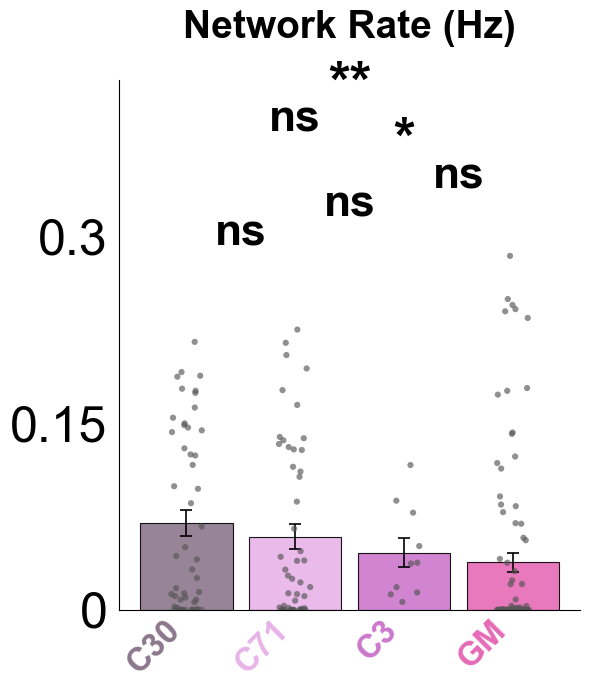


--- WELL-LEVEL NETWORK (BAR PLOT): mixed model, random intercept per well (n=200, wells=20) ---
       term        p  sig
      group  0.00967   **
        age 7.39e-41 ****
group x age    0.103   ns
Overall group differences (Holm):
group1 group2    diff   p-adj sig
    C3    C30  0.0297       1  ns
    C3    C71  0.0025       1  ns
    C3     GM -0.0716    0.76  ns
   C30    C71 -0.0272       1  ns
   C30     GM  -0.101 0.00167  **
   C71     GM -0.0741  0.0393   *
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns       ns         ns      ****        ns
  2.5        ns        ns       ns         ns        ns        ns
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        ns        ns
  3.0        ns        ns       ns         ns         *         *
  3.4        ns        ns       ns         ns        ns        ns
  3.9  

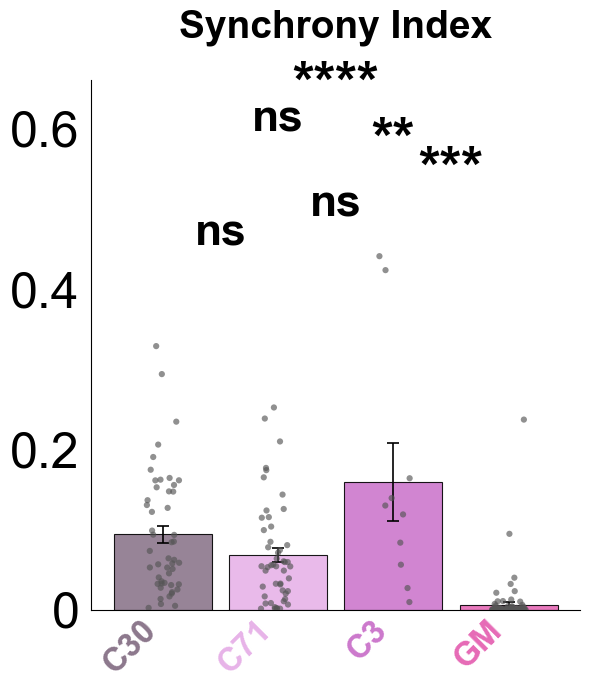


--- WELL-LEVEL SYNCHRONY (BAR PLOT): mixed model, random intercept per well (n=197, wells=20) ---
       term        p  sig
      group  0.00022  ***
        age 1.65e-12 ****
group x age 1.72e-20 ****
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30 -0.0525    0.313   ns
    C3    C71 -0.0801   0.0913   ns
    C3     GM   -0.14  0.00053  ***
   C30    C71 -0.0277    0.313   ns
   C30     GM -0.0872 1.32e-05 ****
   C71     GM -0.0596  0.00482   **
Per-age group differences (Holm across all ages x pairs):
 Time C3 vs C30 C3 vs C71 C3 vs GM C30 vs C71 C30 vs GM C71 vs GM
  2.4        ns        ns       ns         ns        ns        ns
  2.5        ns        ns       ns         ns        ns        ns
  2.6        ns        ns       ns         ns        ns        ns
  2.8        ns        ns       ns         ns        **        ns
  3.0        ns        ns        *         ns       ***        ns
  3.4        ns        ns       ns         ns        **  

In [15]:
run_grouped_analysis_by_clone(exp1_df, experiment="Exp1", save_dir=f"{TRAJ_DIR}/supplementary")


--- GENERATING CLONE PLOTS FOR FIRING ---


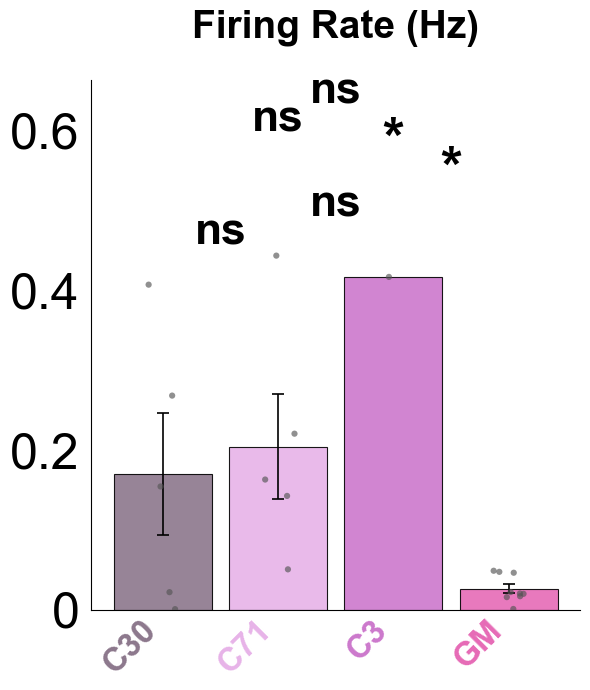

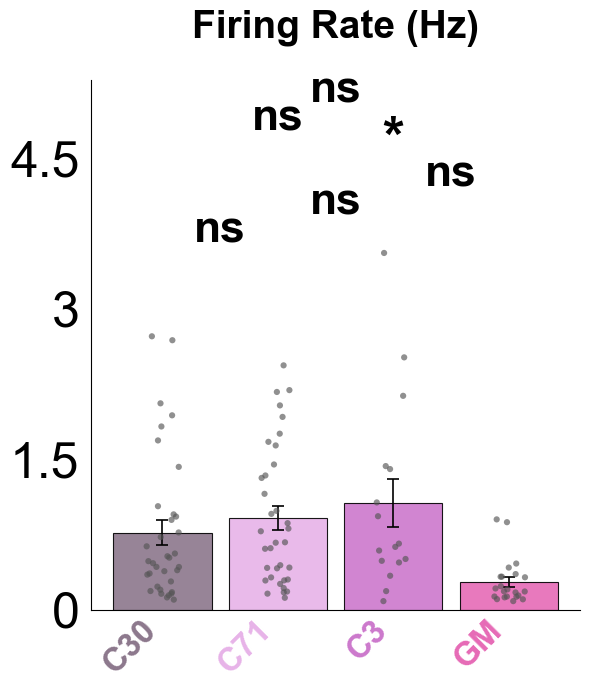


--- WELL-LEVEL FIRING (BAR PLOT): OLS, one observation per well (n=20, wells=20) ---
 term       p sig
group 0.00293  **
Overall group differences (Holm):
group1 group2   diff  p-adj sig
    C3    C30 -0.274   0.33  ns
    C3    C71 -0.191  0.529  ns
    C3     GM -0.448  0.036   *
   C30    C71 0.0828  0.529  ns
   C30     GM -0.174  0.163  ns
   C71     GM -0.257 0.0152   *

--- ELECTRODE-LEVEL FIRING (BAR PLOT): mixed model, random intercept per well (n=108, wells=18) ---
 term      p sig
group 0.0268   *
Overall group differences (Holm):
group1 group2    diff  p-adj sig
    C3    C30 -0.0992  0.689  ns
    C3    C71 0.00986  0.927  ns
    C3     GM  -0.293  0.135  ns
   C30    C71   0.109   0.51  ns
   C30     GM  -0.194   0.25  ns
   C71     GM  -0.303 0.0156   *

--- GENERATING CLONE PLOTS FOR BURST ---


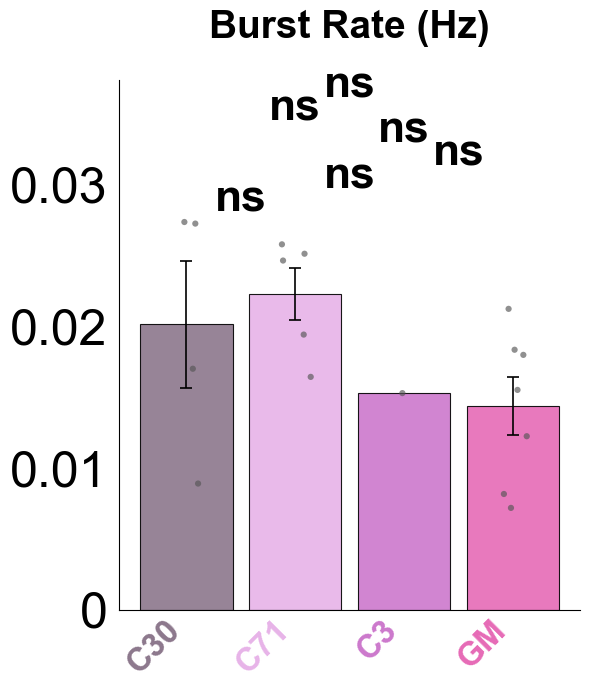

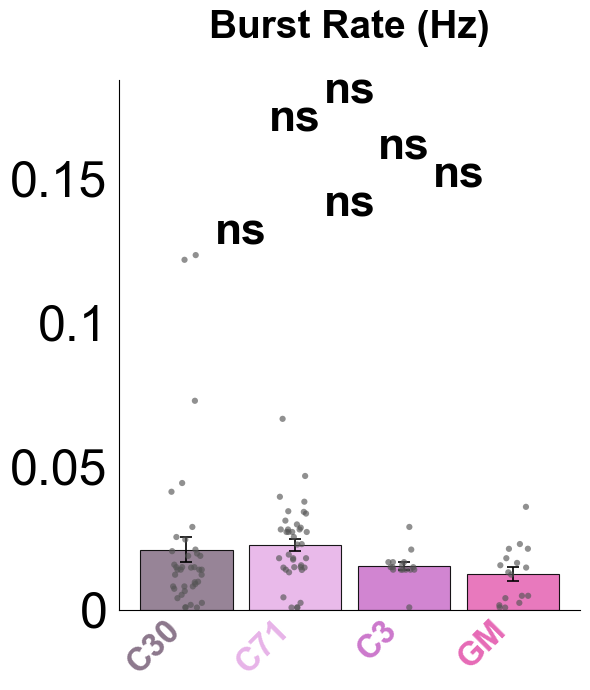


--- WELL-LEVEL BURST (BAR PLOT): OLS, one observation per well (n=17, wells=17) ---
 term     p sig
group 0.145  ns
Overall group differences (Holm):
group1 group2     diff  p-adj sig
    C3    C30  0.00887      1  ns
    C3    C71   0.0226      1  ns
    C3     GM -0.00552      1  ns
   C30    C71   0.0138      1  ns
   C30     GM  -0.0144      1  ns
   C71     GM  -0.0282  0.289  ns

--- ELECTRODE-LEVEL BURST (BAR PLOT): mixed model, random intercept per well (n=110, wells=17) ---
 term     p sig
group 0.212  ns
Overall group differences (Holm):
group1 group2    diff  p-adj sig
    C3    C30 0.00236      1  ns
    C3    C71  0.0205  0.933  ns
    C3     GM -0.0128      1  ns
   C30    C71  0.0182   0.77  ns
   C30     GM -0.0151      1  ns
   C71     GM -0.0333  0.403  ns

--- GENERATING CLONE PLOTS FOR NETWORK ---


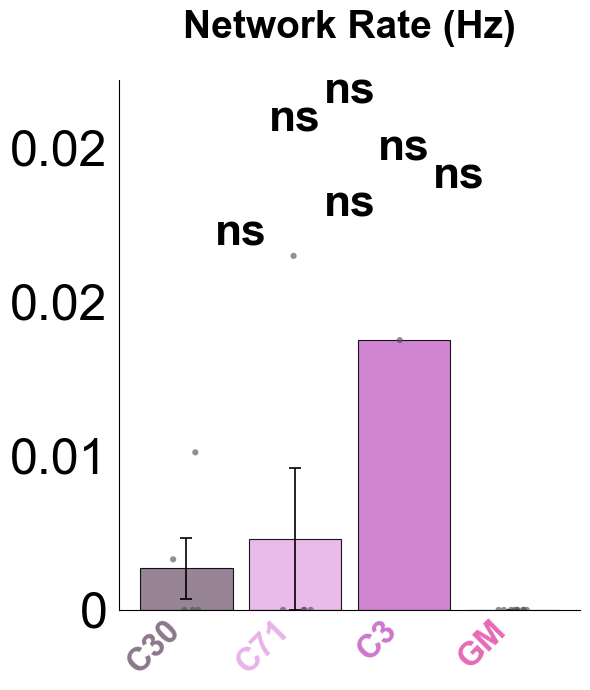


--- WELL-LEVEL NETWORK (BAR PLOT): OLS, one observation per well (n=20, wells=20) ---
 term      p sig
group 0.0387   *
Overall group differences (Holm):
group1 group2     diff  p-adj sig
    C3    C30    -0.08  0.288  ns
    C3    C71  -0.0812  0.288  ns
    C3     GM   -0.106 0.0637  ns
   C30    C71 -0.00122  0.959  ns
   C30     GM  -0.0263  0.648  ns
   C71     GM  -0.0251  0.648  ns

--- GENERATING CLONE PLOTS FOR SYNCHRONY ---


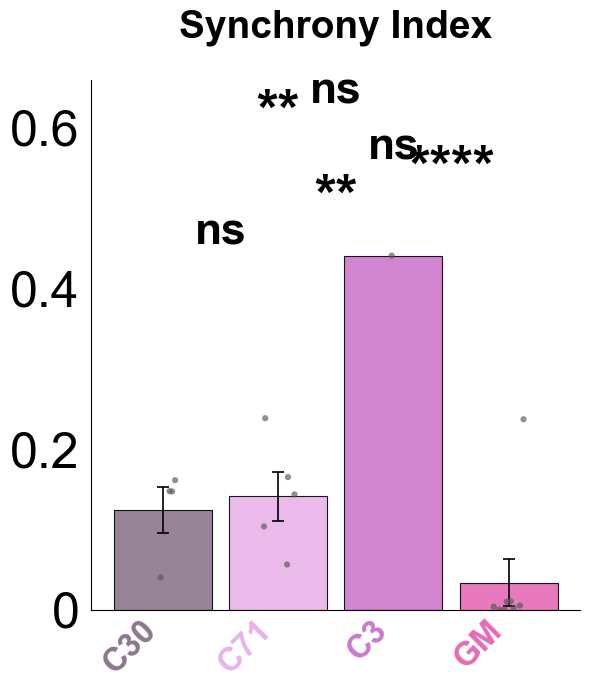


--- WELL-LEVEL SYNCHRONY (BAR PLOT): OLS, one observation per well (n=18, wells=18) ---
 term        p sig
group 0.000323 ***
Overall group differences (Holm):
group1 group2    diff    p-adj  sig
    C3    C30  -0.308  0.00121   **
    C3    C71  -0.278  0.00324   **
    C3     GM  -0.373 3.76e-05 ****
   C30    C71  0.0303    0.542   ns
   C30     GM -0.0649    0.348   ns
   C71     GM -0.0952   0.0737   ns


In [16]:
run_grouped_analysis_by_clone(oldest_df, experiment="Exp1", save_dir=f"{OLDEST_DIR}/supplementary")